<a href="https://colab.research.google.com/github/exyde01-sketch/Artefactos/blob/main/Menu.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# ============================================================
# EQUIPO 6: EXTENDED INFOMAX ICA
# Algoritmo para Google Colab
# Versión unificada con implementación completa de ica_artefactos.py
# ============================================================
#
# ⚠ INSTRUCCIONES DE USO EN GOOGLE COLAB ⚠
# ─────────────────────────────────────────────────────────────
# Colab cierra la conexión con input() si la celda lleva más de
# ~90 segundos inactiva ("localhost rechazó la conexión").
# Para evitarlo, usa DOS celdas separadas:
#
# ┌─ CELDA 1 (ejecutar UNA sola vez al inicio) ───────────────┐
# │  Pega TODO este archivo. Define todas las funciones.       │
# └────────────────────────────────────────────────────────────┘
#
# ┌─ CELDA 2 (ejecutar cada vez que quieras procesar) ────────┐
# │                                                            │
# │  mostrar_menu()                                            │
# │  opcion = input("Selecciona una opción (0-7): ").strip()   │
# │  if opcion == "0":                                         │
# │      print("Saliendo. ¡Hasta pronto!")                     │
# │  else:                                                     │
# │      ejecutar_equipo(opcion)                               │
# │                                                            │
# └────────────────────────────────────────────────────────────┘
#
# Con este patrón:
#   ✓ La celda termina en cuanto ejecutar_equipo() retorna.
#   ✓ El ZIP se descarga automáticamente al terminar el proceso.
#   ✓ Nunca se alcanza el timeout de Colab.
#   ✓ Para procesar otro equipo, simplemente vuelves a
#     ejecutar la Celda 2.
# ─────────────────────────────────────────────────────────────

# ============================================================
# 1. INSTALACIÓN DE DEPENDENCIAS
# ============================================================

import importlib.util
import subprocess
import sys

dependencias = {
    "numpy":      "numpy",
    "pandas":     "pandas",
    "matplotlib": "matplotlib",
    "scipy":      "scipy",
    "sklearn":    "scikit-learn",
}

for modulo, paquete in dependencias.items():
    if importlib.util.find_spec(modulo) is None:
        print(f"Instalando dependencia: {paquete}")
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", paquete
        ])

# python-docx (opcional — para el informe Word)
try:
    import docx  # noqa: F401
except ImportError:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "python-docx"
    ])


# ============================================================
# 2. IMPORTACIONES
# ============================================================

import shutil
import time
import warnings
import zipfile
from pathlib import Path

import matplotlib
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import signal as scipy_signal
from sklearn.decomposition import FastICA

warnings.filterwarnings("ignore")

# python-docx (informe Word)
try:
    from docx import Document
    from docx.shared import Inches, Pt, RGBColor
    DOCX_OK = True
except ImportError:
    DOCX_OK = False
    print("[AVISO] python-docx no disponible. El informe Word se omitirá.")

from IPython.display import display


# ============================================================
# 3. CONFIGURACIÓN
# ============================================================

# Frecuencia de muestreo por defecto (Emotiv EPOC ~8 Hz).
# Se detecta automáticamente desde el Timestamp cuando es posible.
FS_DEFAULT = 8.0

# Canales frontales del Emotiv EPOC (más afectados por artefactos oculares)
CANALES_FRONTALES = {"AF3", "AF4", "F7", "F8", "F3", "F4"}

# Bandas que más se contaminan con artefactos oculares
BANDAS_SENSIBLES = ["theta", "alpha"]

# Colores para las gráficas
COLOR_ORIG = "#1f77b4"   # azul  → señal original
COLOR_CORR = "#2ca02c"   # verde → señal corregida
COLOR_ART  = "#d62728"   # rojo  → región de artefacto

# Umbrales de clasificación
UMBRAL_KURT  = 3.0   # kurtosis mínima para sospechar componente ocular
UMBRAL_AMP   = 2.5   # σ mínimas de amplitud relativa
SCORE_MINIMO = 2     # criterios mínimos (de 4) para marcar como ocular

# Máximo de canales mostrados en la gráfica comparativa
MAX_CANALES_COMPARACION = 4

# Máximo de iteraciones ICA
MAX_ITERACIONES_ICA = 2000


# ============================================================
# 4. CARGA Y PREPROCESAMIENTO
# ============================================================

def cargar_eeg(ruta: Path):
    """
    Carga el CSV Emotiv EPOC y extrae:
      - df_orig  : DataFrame completo sin modificar
      - canales  : lista de canales únicos (AF3, F7, …)
      - columnas : lista de columnas de señal (Canal/banda)
      - fs       : frecuencia de muestreo estimada desde el Timestamp
    """
    df = pd.read_csv(ruta)
    df.columns = df.columns.str.strip()

    # Eliminar columnas extra (Hora, Fecha) si existen
    cols_extra = [c for c in df.columns if c.lower() in ("hora", "fecha")]
    if cols_extra:
        df = df.drop(columns=cols_extra)

    columnas = [c for c in df.columns if c != "Timestamp"]

    # Convertir columnas string a numérico
    for col in columnas:
        if df[col].dtype == object or str(df[col].dtype) == "str":
            df[col] = pd.to_numeric(
                df[col].astype(str).str.strip(), errors="coerce"
            )

    # Canales únicos (parte antes de '/')
    canales = list(dict.fromkeys(c.split("/")[0] for c in columnas))

    # Estimar Fs desde el Timestamp
    if "Timestamp" in df.columns and len(df) > 1:
        ts    = pd.to_numeric(df["Timestamp"], errors="coerce")
        delta = ts.diff().dropna().median()
        fs    = round(1.0 / delta, 2) if (delta and delta > 0) else FS_DEFAULT
    else:
        fs = FS_DEFAULT

    return df, canales, columnas, fs


def preparar_datos_csv(ruta_csv: Path):
    """
    Lee y valida el CSV para el pipeline Colab:
      - Detecta columna temporal.
      - Convierte señales a numérico.
      - Interpola valores ausentes.
      - Verifica canales constantes y mínimo de muestras.

    Devuelve:
        df_original, datos, nombres_canales, columna_temporal, tiempo
    """
    df_original = pd.read_csv(ruta_csv)

    if df_original.empty:
        raise ValueError("El archivo CSV está vacío.")

    print(f"  Filas    : {len(df_original)}")
    print(f"  Columnas : {list(df_original.columns)}")

    columnas_tiempo = {"timestamp", "time", "datetime", "fecha", "tiempo", "date"}
    columna_temporal = next(
        (c for c in df_original.columns
         if str(c).strip().lower() in columnas_tiempo),
        None,
    )

    tiempo = df_original[columna_temporal].copy() if columna_temporal is not None else None

    columnas_senales = [c for c in df_original.columns if c != columna_temporal]

    senales_df = df_original[columnas_senales].apply(pd.to_numeric, errors="coerce")

    columnas_vacias = senales_df.columns[senales_df.isna().all()].tolist()
    if columnas_vacias:
        print("  Columnas ignoradas (sin datos numéricos):", columnas_vacias)
        senales_df = senales_df.drop(columns=columnas_vacias)

    if senales_df.shape[1] < 2:
        raise ValueError(
            "Se necesitan al menos dos canales numéricos. "
            "Comprueba las columnas del archivo."
        )

    senales_df = senales_df.replace([np.inf, -np.inf], np.nan)

    faltantes = int(senales_df.isna().sum().sum())
    if faltantes > 0:
        print(f"  Valores ausentes: {faltantes} → interpolando…")
        senales_df = senales_df.interpolate(
            method="linear", axis=0, limit_direction="both"
        )
        if senales_df.isna().any().any():
            raise ValueError(
                "Persisten valores ausentes después de la interpolación."
            )

    datos           = senales_df.to_numpy(dtype=float)
    nombres_canales = senales_df.columns.tolist()

    if not np.isfinite(datos).all():
        raise ValueError("Persisten valores no finitos en las señales.")

    if len(datos) < 10:
        raise ValueError("El archivo contiene muy pocas muestras para ICA.")

    desviaciones       = np.std(datos, axis=0)
    canales_constantes = [nombres_canales[i] for i, d in enumerate(desviaciones) if d < 1e-12]
    if canales_constantes:
        raise ValueError(
            "Se detectaron canales constantes: "
            + ", ".join(map(str, canales_constantes))
        )

    return df_original, datos, nombres_canales, columna_temporal, tiempo


# ============================================================
# 5. PREPARAR MATRIZ ICA
# ============================================================

def preparar_matriz_ica(df: pd.DataFrame, canales: list,
                        columnas: list, banda: str = "theta"):
    """
    Extrae la potencia de UNA banda por canal → matriz (N, 14).
    Se usa theta porque es la más afectada por artefactos oculares.
    """
    cols_ica = [c for c in columnas if c.endswith("/" + banda)]
    if len(cols_ica) < 2:
        cols_ica = columnas   # fallback: todas las bandas

    X = df[cols_ica].values.astype(np.float64)
    # Rellenar NaN con media de columna
    for j in range(X.shape[1]):
        mask = np.isnan(X[:, j])
        if mask.any():
            X[mask, j] = np.nanmean(X[:, j])

    return X, cols_ica


# ============================================================
# 6. EXTENDED INFOMAX ICA (implementación propia)
# ============================================================

class ExtendedInfomaxICA:
    """
    Extended Infomax ICA (Bell & Sejnowski 1995; Lee et al. 1999).

    Diferencia clave frente a ICA convencional:
      - ICA convencional asume todas las fuentes super-gaussianas.
      - Extended Infomax adapta la función de activación por componente:
            g(y) = tanh(y)         → fuente sub-gaussiana  (kurt > 0)
            g(y) = y − tanh(y)    → fuente super-gaussiana (kurt < 0)
      Esto permite separar fuentes sub- y super-gaussianas
      simultáneamente, esencial en EEG real.
    """

    def __init__(self, n_components=None, lr=0.005, max_iter=2000,
                 tol=1e-4, random_state=42):
        self.n_components = n_components
        self.lr           = lr
        self.max_iter     = max_iter
        self.tol          = tol
        self.random_state = random_state
        self.W_           = None   # desmezcla (n, p)
        self.A_           = None   # mezcla    (p, n)
        self.mean_        = None
        self.components_  = None

    def _blanquear(self, X):
        cov       = np.cov(X, rowvar=False)
        vals, vecs = np.linalg.eigh(cov)
        idx        = np.argsort(vals)[::-1]
        vals, vecs = vals[idx], vecs[:, idx]
        n          = self.n_components
        vals, vecs = vals[:n], vecs[:, :n]
        D_inv      = np.diag(1.0 / np.sqrt(vals + 1e-10))
        W_w        = D_inv @ vecs.T          # (n, p) blanqueamiento
        W_dw       = vecs @ np.diag(np.sqrt(vals + 1e-10))
        return X @ W_w.T, W_w, W_dw

    def fit(self, X: np.ndarray):
        rng        = np.random.RandomState(self.random_state)
        self.mean_ = X.mean(axis=0)
        Xc         = X - self.mean_
        if self.n_components is None:
            self.n_components = Xc.shape[1]

        n, N       = self.n_components, Xc.shape[0]
        Xw, W_w, _ = self._blanquear(Xc)
        W, _       = np.linalg.qr(rng.randn(n, n))
        delta      = np.inf

        for it in range(self.max_iter):
            y = W @ Xw.T        # (n, N)

            # Función de activación adaptativa (clave de Extended Infomax)
            kurt = np.mean(y ** 4, axis=1) - 3 * np.mean(y ** 2, axis=1) ** 2
            g    = np.where(
                kurt[:, None] > 0,
                np.tanh(y),           # sub-gaussiana
                y - np.tanh(y),       # super-gaussiana
            )

            dW    = (np.eye(n) - (g @ y.T) / N) @ W
            W_new = W + self.lr * dW
            W_new, _ = np.linalg.qr(W_new.T)
            W_new    = W_new.T

            delta = np.max(np.abs(W_new - W))
            W     = W_new
            if delta < self.tol:
                print(f"      Extended Infomax convergió en it={it + 1} (Δ={delta:.2e})")
                break
        else:
            print(f"      Extended Infomax: {self.max_iter} iteraciones (Δ={delta:.2e})")

        self.W_          = W @ W_w
        self.A_          = np.linalg.pinv(self.W_)
        self.components_ = self.W_
        return self

    def transform(self, X: np.ndarray) -> np.ndarray:
        return (X - self.mean_) @ self.W_.T

    def inverse_transform(self, S: np.ndarray) -> np.ndarray:
        return S @ self.A_.T + self.mean_


# ============================================================
# 7. CLASIFICACIÓN DE COMPONENTES (4 CRITERIOS)
# ============================================================

def clasificar_componentes(S: np.ndarray, canales_ica: list,
                           A: np.ndarray, fs: float) -> dict:
    """
    Clasifica cada componente como ocular o cerebral.

    Criterios (se necesitan ≥ SCORE_MINIMO para marcar como ocular):
      1. Kurtosis > UMBRAL_KURT
      2. Proyección dominante en canales frontales (AF3/AF4/F7/F8/F3/F4)
      3. Potencia concentrada en bajas frecuencias (< fs/4)
      4. Amplitud relativa > UMBRAL_AMP σ
    """
    n              = S.shape[1]
    nombres_canales = [c.split("/")[0] for c in canales_ica]
    idx_front       = [i for i, c in enumerate(nombres_canales)
                       if c in CANALES_FRONTALES]

    clasif = {}
    for i in range(n):
        comp    = S[:, i]
        m, sd   = comp.mean(), comp.std() + 1e-12
        kurt    = float(np.mean(((comp - m) / sd) ** 4) - 3.0)
        amp_rel = float(np.max(np.abs(comp)) / sd)

        topo    = np.abs(A[:, i])
        p_front = (float(topo[idx_front].sum() / (topo.sum() + 1e-12))
                   if idx_front else 0.0)

        freqs, psd = scipy_signal.welch(
            comp, fs=fs, nperseg=min(128, len(comp) // 4)
        )
        ratio_baja = float(psd[freqs < fs / 4].sum() / (psd.sum() + 1e-12))

        score, razones = 0, []
        if abs(kurt)   > UMBRAL_KURT:  score += 1; razones.append(f"kurt={kurt:.2f}")
        if p_front     > 0.20:         score += 1; razones.append(f"frontal={p_front:.0%}")
        if ratio_baja  > 0.40:         score += 1; razones.append(f"baja-freq={ratio_baja:.0%}")
        if amp_rel     > UMBRAL_AMP:   score += 1; razones.append(f"amp={amp_rel:.1f}σ")

        ocular      = score >= SCORE_MINIMO
        clasif[i]   = {
            "es_ocular":  ocular,
            "score":      score,
            "kurt":       kurt,
            "amp_rel":    amp_rel,
            "p_front":    p_front,
            "ratio_baja": ratio_baja,
            "razones":    razones,
            "topo":       A[:, i].tolist(),
        }
        tag = "ARTEFACTO OCULAR" if ocular else "Actividad cerebral"
        print(f"      IC{i:02d} → {tag:<20} score={score}/4"
              + (f" | {'; '.join(razones)}" if razones else ""))

    return clasif


# ============================================================
# 8. ICA CONVENCIONAL (COMPARACIÓN — FastICA)
# ============================================================

def ica_convencional(X: np.ndarray, n_comp: int,
                     canales_ica: list, fs: float):
    """
    Aplica ICA convencional (FastICA de scikit-learn) como método
    de comparación. Usa los mismos 4 criterios de clasificación.
    """
    media       = X.mean(axis=0)
    Xc          = X - media
    sd          = Xc.std(axis=0)
    sd[sd < 1e-12] = 1.0
    Xn          = Xc / sd

    ica = FastICA(n_components=n_comp, random_state=42,
                  max_iter=2000, tol=1e-4)
    S   = ica.fit_transform(Xn)
    A   = ica.mixing_

    clasif   = clasificar_componentes(S, canales_ica, A, fs)
    oculares = [i for i, v in clasif.items() if v["es_ocular"]]

    S_lim = S.copy()
    for i in oculares:
        S_lim[:, i] = 0.0

    X_rec = S_lim @ ica.components_ * sd + media
    return X_rec, oculares, clasif


# ============================================================
# 9. DETECCIÓN DE SEGMENTOS CONTAMINADOS
# ============================================================

def detectar_segmentos(X_orig: np.ndarray, X_corr: np.ndarray,
                       canales_ica: list, fs: float,
                       umbral_std: float = 2.0) -> list:
    """
    Localiza las ventanas temporales donde el artefacto es mayor
    comparando la diferencia absoluta entre señal original y corregida.
    """
    diff       = np.abs(X_orig - X_corr)
    canal_idx  = int(np.argmax(diff.mean(axis=0)))
    canal_nom  = canales_ica[canal_idx].split("/")[0]
    señal_diff = diff[:, canal_idx]

    umbral = señal_diff.mean() + umbral_std * señal_diff.std()
    picos, _ = scipy_signal.find_peaks(
        señal_diff, height=umbral,
        distance=max(1, int(fs * 0.5)),
    )

    ventana = max(1, int(fs * 0.6))
    segs    = []
    for pk in picos:
        i0 = max(0, pk - ventana)
        i1 = min(len(señal_diff) - 1, pk + ventana)
        segs.append({
            "inicio_m": int(i0),    "fin_m":  int(i1),
            "inicio_s": i0 / fs,    "fin_s":  i1 / fs,
            "dur_s":    (i1 - i0) / fs,
            "dur_ms":   (i1 - i0) / fs * 1000,
            "canal":    canal_nom,
            "amp_diff": float(señal_diff[pk]),
        })
    return segs


# ============================================================
# 10. GRÁFICAS
# ============================================================

def _tiempo(df: pd.DataFrame, fs: float) -> np.ndarray:
    if "Timestamp" in df.columns:
        t = df["Timestamp"].values
        return t - t[0]
    return np.arange(len(df)) / fs


def graficar_señal_general(df, canales, columnas, fs, segs, nombre, ruta):
    """Potencia theta de cada canal + regiones de artefacto marcadas."""
    cols_theta = [c for c in columnas if c.endswith("/theta")][:8]
    n = len(cols_theta)
    t = _tiempo(df, fs)

    fig, axes = plt.subplots(n, 1, figsize=(14, 2.4 * n), sharex=True)
    if n == 1:
        axes = [axes]

    for ax, col in zip(axes, cols_theta):
        canal = col.split("/")[0]
        ax.plot(t, df[col].values, color=COLOR_ORIG, linewidth=0.9)
        for s in segs:
            ax.axvspan(s["inicio_s"], s["fin_s"], alpha=0.22, color=COLOR_ART)
        ax.set_ylabel(f"{canal}\nθ-power", fontsize=7)
        ax.grid(alpha=0.2)

    axes[-1].set_xlabel("Tiempo (s)")
    p_orig = mpatches.Patch(color=COLOR_ORIG, label="Potencia θ original")
    p_art  = mpatches.Patch(color=COLOR_ART, alpha=0.4, label="Región artefacto ocular")
    axes[0].legend(handles=[p_orig, p_art], fontsize=8, loc="upper right")
    fig.suptitle(f"Señal EEG original — {nombre}", fontsize=11, fontweight="bold")
    fig.tight_layout()
    fig.savefig(str(ruta), dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print(f"      → {ruta.name}")


def graficar_componentes(S, clasif, canales_ica, A, fs, ruta_dir):
    """Una figura por componente ICA: serie temporal + topografía por canal."""
    t       = np.arange(S.shape[0]) / fs
    nombres = [c.split("/")[0] for c in canales_ica]

    for i, v in clasif.items():
        comp   = S[:, i]
        ocular = v["es_ocular"]
        color  = COLOR_ART if ocular else COLOR_ORIG

        fig, (ax1, ax2) = plt.subplots(
            1, 2, figsize=(12, 3), gridspec_kw={"width_ratios": [3, 1]}
        )
        ax1.plot(t, comp, color=color, linewidth=0.7)
        titulo = "ARTEFACTO OCULAR" if ocular else "Actividad cerebral"
        ax1.set_title(
            f"IC{i:02d} — {titulo}  |  score={v['score']}/4  kurt={v['kurt']:.2f}",
            fontsize=9,
        )
        ax1.set_xlabel("Tiempo (s)")
        ax1.set_ylabel("Amplitud (UA)")
        ax1.grid(alpha=0.25)
        if ocular:
            ax1.set_facecolor("#fff5f5")

        topo     = np.array(v["topo"])
        col_barra = [COLOR_ART if c in CANALES_FRONTALES else "steelblue" for c in nombres]
        ax2.barh(range(len(nombres)), topo, color=col_barra)
        ax2.set_yticks(range(len(nombres)))
        ax2.set_yticklabels(nombres, fontsize=7)
        ax2.set_xlabel("Peso (UA)")
        ax2.set_title("Topografía")
        ax2.grid(alpha=0.2)

        raz = "; ".join(v["razones"]) if v["razones"] else "Sin criterios"
        fig.text(0.5, -0.02, f"Criterios: {raz}", ha="center", fontsize=8, style="italic")
        fig.tight_layout()
        ruta = ruta_dir / f"IC{i:02d}.png"
        fig.savefig(str(ruta), dpi=150, bbox_inches="tight")
        plt.show()
        plt.close(fig)
        print(f"      → {ruta.name}")


def graficar_antes_despues(df_orig, df_corr, columnas, fs, segs, ruta, titulo):
    """Superposición azul (original) / verde (corregido) de señales theta."""
    cols = [c for c in columnas if c.endswith("/theta")][:4]
    t    = _tiempo(df_orig, fs)
    n    = len(cols)

    fig, axes = plt.subplots(n, 1, figsize=(14, 3 * n), sharex=True)
    if n == 1:
        axes = [axes]

    for ax, col in zip(axes, cols):
        canal = col.split("/")[0]
        ax.plot(t, df_orig[col].values, color=COLOR_ORIG,
                lw=1.0, alpha=0.85, label="Original")
        ax.plot(t, df_corr[col].values, color=COLOR_CORR,
                lw=1.0, alpha=0.90, label="Corregido")
        for s in segs:
            ax.axvspan(s["inicio_s"], s["fin_s"], alpha=0.18, color=COLOR_ART)
        ax.set_ylabel(f"{canal} θ")
        ax.grid(alpha=0.2)
        handles = [
            plt.Line2D([0], [0], color=COLOR_ORIG, label="Original (azul)"),
            plt.Line2D([0], [0], color=COLOR_CORR, label="Corregido (verde)"),
            mpatches.Patch(color=COLOR_ART, alpha=0.3, label="Artefacto (rojo)"),
        ]
        ax.legend(handles=handles, fontsize=8, loc="upper right")

    axes[-1].set_xlabel("Tiempo (s)")
    fig.suptitle(titulo, fontsize=11, fontweight="bold")
    fig.tight_layout()
    fig.savefig(str(ruta), dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print(f"      → {ruta.name}")


def graficar_zoom(df_orig, df_corr, columnas, fs, segs, ruta_dir):
    """Zoom ampliado de cada segmento de artefacto detectado."""
    if not segs:
        return
    cols_theta = [c for c in columnas if c.endswith("/theta")]
    if not cols_theta:
        return
    col   = cols_theta[0]
    canal = col.split("/")[0]
    t     = _tiempo(df_orig, fs)

    for idx, s in enumerate(segs):
        margen = max(1, int(fs * 1.0))
        i0     = max(0, s["inicio_m"] - margen)
        i1     = min(len(df_orig) - 1, s["fin_m"] + margen)

        fig, ax = plt.subplots(figsize=(10, 4))
        ax.plot(t[i0:i1], df_orig[col].values[i0:i1],
                color=COLOR_ORIG, lw=1.3, label="Original")
        ax.plot(t[i0:i1], df_corr[col].values[i0:i1],
                color=COLOR_CORR, lw=1.3, label="Corregido")
        ax.axvspan(s["inicio_s"], s["fin_s"],
                   alpha=0.22, color=COLOR_ART, label="Artefacto")
        ax.axvline(s["inicio_s"], color=COLOR_ART, ls="--", lw=1.0)
        ax.axvline(s["fin_s"],    color=COLOR_ART, ls="--", lw=1.0)
        ax.set_title(
            f"Zoom artefacto #{idx + 1} — Canal: {canal} (θ)\n"
            f"Inicio: {s['inicio_s']:.3f}s | Fin: {s['fin_s']:.3f}s | "
            f"Duración: {s['dur_ms']:.0f} ms",
            fontsize=9,
        )
        ax.set_xlabel("Tiempo (s)")
        ax.set_ylabel(f"{canal} θ-power")
        ax.legend(fontsize=9)
        ax.grid(alpha=0.25)
        fig.tight_layout()
        ruta = ruta_dir / f"zoom_{idx + 1:02d}.png"
        fig.savefig(str(ruta), dpi=150, bbox_inches="tight")
        plt.show()
        plt.close(fig)
        print(f"      → {ruta.name}")


def graficar_comparacion(df_orig, df_ext, df_conv, columnas, fs, ruta):
    """Tres señales superpuestas: original / ICA conv. / Ext. Infomax."""
    cols = [c for c in columnas if c.endswith("/theta")][:3]
    t    = _tiempo(df_orig, fs)
    n    = len(cols)

    fig, axes = plt.subplots(n, 1, figsize=(14, 3.2 * n), sharex=True)
    if n == 1:
        axes = [axes]

    for ax, col in zip(axes, cols):
        canal = col.split("/")[0]
        ax.plot(t, df_orig[col].values,  color=COLOR_ORIG, lw=1.0,
                alpha=0.70, label="Original")
        ax.plot(t, df_conv[col].values, color="orange",   lw=1.0,
                alpha=0.85, label="ICA Convencional")
        ax.plot(t, df_ext[col].values,  color=COLOR_CORR, lw=1.0,
                alpha=0.95, label="Extended Infomax ICA")
        ax.set_ylabel(f"{canal} θ")
        ax.grid(alpha=0.2)
        ax.legend(fontsize=8, loc="upper right")

    axes[-1].set_xlabel("Tiempo (s)")
    fig.suptitle(
        "Comparación: Original  vs  ICA Convencional  vs  Extended Infomax ICA",
        fontsize=11, fontweight="bold",
    )
    fig.tight_layout()
    fig.savefig(str(ruta), dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print(f"      → {ruta.name}")


# ============================================================
# 11. MÉTRICAS
# ============================================================

def calcular_metricas(X_orig, X_ext, X_conv,
                      n_ext, n_conv, n_total,
                      t_ext, t_conv) -> dict:
    def _m(o, c):
        eps  = 1e-12
        o_f  = o.flatten()
        c_f  = c.flatten()
        amp_o = float(np.max(np.abs(o_f)))
        amp_c = float(np.max(np.abs(c_f)))
        var_o = float(np.var(o_f))
        var_c = float(np.var(c_f))
        return {
            "amp_orig":     amp_o,
            "amp_corr":     amp_c,
            "red_amp":      (amp_o - amp_c) / (amp_o + eps) * 100,
            "std_orig":     float(np.std(o_f)),
            "std_corr":     float(np.std(c_f)),
            "var_orig":     var_o,
            "var_corr":     var_c,
            "red_var":      (var_o - var_c) / (var_o + eps) * 100,
            "energia_orig": float(np.sum(o_f ** 2)),
            "energia_corr": float(np.sum(c_f ** 2)),
            "correlacion":  float(np.corrcoef(o_f, c_f)[0, 1]),
        }

    return {
        "n_ext":    n_ext,
        "n_conv":   n_conv,
        "n_total":  n_total,
        "pct_ext":  n_ext  / n_total * 100 if n_total else 0,
        "pct_conv": n_conv / n_total * 100 if n_total else 0,
        "t_ext":    t_ext,
        "t_conv":   t_conv,
        "ext":      _m(X_orig, X_ext),
        "conv":     _m(X_orig, X_conv),
    }


# ============================================================
# 12. INFORME WORD (opcional)
# ============================================================

def generar_informe(carpeta_salida: Path, archivos_proc: list,
                    resumen_global: dict):
    if not DOCX_OK:
        print("  [OMITIDO] Instalar python-docx para generar el informe Word.")
        return None

    doc = Document()

    def h1(t): doc.add_heading(t, level=1)
    def h2(t): doc.add_heading(t, level=2)
    def p(t):  doc.add_paragraph(t)

    def img_fig(ruta, caption, w=5.5):
        ruta = Path(ruta)
        if ruta.exists():
            doc.add_picture(str(ruta), width=Inches(w))
        else:
            p(f"[Imagen no disponible: {ruta.name}]")
        par           = doc.add_paragraph(caption)
        par.runs[0].italic         = True
        par.runs[0].font.size      = Pt(9)
        par.runs[0].font.color.rgb = RGBColor(0x44, 0x44, 0x44)
        doc.add_paragraph("")

    # Portada
    doc.add_heading("ANÁLISIS DE ARTEFACTOS EEG — EQUIPO 6", 0)
    p(
        "Actividad : Investigación, Identificación y Eliminación de Artefactos\n"
        "Equipo    : 6\n"
        "Artefacto : Artefactos oculares\n"
        "Método principal : Extended Infomax ICA\n"
        "Comparación      : ICA convencional (FastICA)\n"
        f"Archivos analizados : {len(archivos_proc)}\n"
        f"Fecha : {pd.Timestamp.now().strftime('%d de %B de %Y')}"
    )
    doc.add_page_break()

    h1("1. Introducción")
    p(
        "El electroencefalograma (EEG) captura la actividad eléctrica del "
        "cerebro. Los datos provienen del dispositivo Emotiv EPOC, que registra "
        "la potencia espectral (θ, α, βL, βH, γ) de 14 canales. Los artefactos "
        "oculares contaminan principalmente los canales frontales (AF3, AF4, F7, "
        "F8, F3, F4) en las bandas theta y alpha."
    )

    h1("2. Extended Infomax ICA")
    p(
        "Extended Infomax (Bell & Sejnowski 1995; Lee et al. 1999) maximiza la "
        "entropía de la salida mediante gradiente natural adaptativo:\n"
        "  ΔW = [I − g(y)·yᵀ] · W\n"
        "  g(y) = tanh(y)        si kurtosis > 0  (sub-gaussiana)\n"
        "  g(y) = y − tanh(y)   si kurtosis < 0  (super-gaussiana)\n\n"
        "ICA convencional (FastICA) usa g(u)=tanh(u) fijo para todos los "
        "componentes. Extended Infomax adapta g por componente, lo que permite "
        "separar fuentes sub- y super-gaussianas coexistentes en EEG real."
    )

    h1("3. Resultados por archivo")
    for info in archivos_proc:
        h2(info["archivo"])
        met = info["met"]
        p(
            f"Muestras: {info['n_muestras']}  |  Fs: {info['fs']:.1f} Hz  "
            f"|  Duración: {info['duracion_s']:.1f} s  |  Canales: {info['n_canales']}\n"
            f"Comp. oculares Extended Infomax : {info['n_ext']} / {info['n_total']}  "
            f"({met['pct_ext']:.1f}%)\n"
            f"Comp. oculares ICA Convencional : {info['n_conv']} / {info['n_total']}  "
            f"({met['pct_conv']:.1f}%)\n"
            f"Reducción amplitud (Ext.): {met['ext']['red_amp']:.1f}%  |  "
            f"Correlación: {met['ext']['correlacion']:.4f}\n"
            f"Segmentos detectados: {info['n_segs']}"
        )

        g = info["dirs_graficas"]
        c = info["dirs_comp"]

        img_fig(g / "señal_general.png",
                "Señal EEG original con regiones de artefacto marcadas en rojo.")
        img_fig(g / "antes_despues.png",
                "Antes (azul) vs. después (verde) de aplicar Extended Infomax ICA.")
        img_fig(g / "comparacion.png",
                "Comparación: Original / ICA Convencional / Extended Infomax ICA.")
        for idx in range(min(info["n_segs"], 3)):
            img_fig(g / f"zoom_{idx + 1:02d}.png",
                    f"Zoom del artefacto #{idx + 1} detectado.")
        for i_ic in info["comp_oculares_ext"]:
            img_fig(c / f"IC{i_ic:02d}.png",
                    f"IC{i_ic:02d} — Componente ocular eliminado.", w=5.0)

    h1("4. Conclusiones")
    sg = resumen_global
    p(
        f"1. Archivos analizados: {sg['n_archivos']}\n"
        f"2. Componentes oculares (Extended Infomax): {sg['total_comp_ext']}\n"
        f"3. Componentes oculares (ICA Convencional): {sg['total_comp_conv']}\n"
        f"4. Reducción de amplitud media: {sg['red_amp_media']:.1f}%\n"
        f"5. Correlación media con señal original: {sg['corr_media']:.4f}\n"
        "Extended Infomax modela fuentes sub- y super-gaussianas gracias a su "
        "función de activación adaptativa, lo que lo hace más robusto para "
        "señales EEG reales respecto a ICA convencional."
    )

    ruta_doc = carpeta_salida / "Informe_Equipo6_EEG_Artefactos_Oculares.docx"
    doc.save(str(ruta_doc))
    print(f"  → Informe Word: {ruta_doc.name}")
    return ruta_doc


# ============================================================
# 13. PIPELINE POR ARCHIVO (núcleo del procesamiento)
# ============================================================

def procesar_archivo_eeg_completo(ruta_csv: Path,
                                   carpeta_salida: Path) -> dict:
    """
    Pipeline completo para un CSV Emotiv EPOC:
      1. Carga y detección automática de Fs
      2. Extended Infomax ICA (implementación propia)
      3. Clasificación con 4 criterios
      4. ICA Convencional (FastICA) como comparación
      5. Detección de segmentos contaminados
      6. 5 tipos de gráficas
      7. CSVs corregidos + tabla de artefactos
      8. Resumen de métricas
    """
    ruta_csv      = Path(ruta_csv)
    carpeta_salida = Path(carpeta_salida)
    carpeta_salida.mkdir(parents=True, exist_ok=True)

    nombre = ruta_csv.name
    print(f"\n{'=' * 60}")
    print(f"Procesando: {nombre}")
    print("=" * 60)

    # ── A. Cargar ────────────────────────────────────────────
    df_orig, canales, columnas, fs = cargar_eeg(ruta_csv)
    n_muestras = len(df_orig)
    print(f"  {n_muestras} muestras | {len(canales)} canales | "
          f"Fs≈{fs:.1f} Hz | dur≈{n_muestras / fs:.0f}s")

    # ── B. Preparar matriz ICA (banda theta, 14 columnas) ────
    X_ica, cols_ica = preparar_matriz_ica(df_orig, canales, columnas, "theta")
    n_comp          = X_ica.shape[1]
    print(f"  Matriz ICA: {X_ica.shape}  ({n_comp} componentes)")

    # ── C. Extended Infomax ICA ──────────────────────────────
    print("  Extended Infomax ICA…")
    t0      = time.time()
    ica_ext = ExtendedInfomaxICA(n_components=n_comp, lr=0.005,
                                  max_iter=MAX_ITERACIONES_ICA,
                                  tol=1e-4, random_state=42)
    ica_ext.fit(X_ica)
    S_ext   = ica_ext.transform(X_ica)
    A_ext   = ica_ext.A_
    t_ext   = time.time() - t0

    # ── D. Clasificar componentes ────────────────────────────
    print("  Clasificando componentes (Extended Infomax)…")
    clasif_ext   = clasificar_componentes(S_ext, cols_ica, A_ext, fs)
    oculares_ext = [i for i, v in clasif_ext.items() if v["es_ocular"]]

    # ── E. Reconstruir señal corregida (Ext. Infomax) ────────
    S_lim = S_ext.copy()
    for i in oculares_ext:
        S_lim[:, i] = 0.0
    X_corr_ext = ica_ext.inverse_transform(S_lim)

    # ── F. Propagar corrección a todas las bandas ────────────
    df_corr_ext  = df_orig[columnas].copy()
    df_corr_conv = df_orig[columnas].copy()

    for j, col_ica in enumerate(cols_ica):
        canal_j = col_ica.split("/")[0]
        with np.errstate(divide="ignore", invalid="ignore"):
            factor_ext = np.where(
                np.abs(X_ica[:, j]) > 1e-10,
                X_corr_ext[:, j] / X_ica[:, j],
                1.0,
            )
        for col_b in [c for c in columnas if c.startswith(canal_j + "/")]:
            df_corr_ext[col_b] = (
                df_corr_ext[col_b].values * np.clip(factor_ext, 0.0, 2.0)
            )

    # ── G. ICA Convencional (FastICA) ────────────────────────
    print("  ICA Convencional (FastICA)…")
    t0c                              = time.time()
    X_corr_conv, oculares_conv, _    = ica_convencional(
        X_ica, n_comp, cols_ica, fs
    )
    t_conv                           = time.time() - t0c

    for j, col_ica in enumerate(cols_ica):
        canal_j = col_ica.split("/")[0]
        with np.errstate(divide="ignore", invalid="ignore"):
            factor_conv = np.where(
                np.abs(X_ica[:, j]) > 1e-10,
                X_corr_conv[:, j] / X_ica[:, j],
                1.0,
            )
        for col_b in [c for c in columnas if c.startswith(canal_j + "/")]:
            df_corr_conv[col_b] = (
                df_corr_conv[col_b].values * np.clip(factor_conv, 0.0, 2.0)
            )

    # Agregar Timestamp a los DataFrames corregidos
    df_ext_out  = df_corr_ext.copy()
    df_conv_out = df_corr_conv.copy()
    if "Timestamp" in df_orig.columns:
        df_ext_out.insert(0,  "Timestamp", df_orig["Timestamp"].values)
        df_conv_out.insert(0, "Timestamp", df_orig["Timestamp"].values)

    # ── H. Detectar segmentos ────────────────────────────────
    segs = detectar_segmentos(X_ica, X_corr_ext, cols_ica, fs)
    print(f"  Segmentos de artefacto detectados: {len(segs)}")

    # ── I. Carpetas de gráficas ──────────────────────────────
    stem  = ruta_csv.stem
    g_dir = carpeta_salida / "graficas"      / stem
    c_dir = carpeta_salida / "componentes"   / stem
    g_dir.mkdir(parents=True, exist_ok=True)
    c_dir.mkdir(parents=True, exist_ok=True)

    # ── J. Gráficas ──────────────────────────────────────────
    print("  Generando gráficas…")
    graficar_señal_general(
        df_orig, canales, columnas, fs, segs, nombre,
        g_dir / "señal_general.png",
    )
    graficar_componentes(S_ext, clasif_ext, cols_ica, A_ext, fs, c_dir)
    graficar_antes_despues(
        df_orig[columnas], df_corr_ext, columnas, fs, segs,
        g_dir / "antes_despues.png",
        f"Antes vs. Después (Ext. Infomax ICA) — {nombre}",
    )
    graficar_zoom(df_orig[columnas], df_corr_ext, columnas, fs, segs, g_dir)
    graficar_comparacion(
        df_orig[columnas], df_corr_ext, df_corr_conv,
        columnas, fs,
        g_dir / "comparacion.png",
    )

    # ── K. Métricas ──────────────────────────────────────────
    met = calcular_metricas(
        X_ica, X_corr_ext, X_corr_conv,
        len(oculares_ext), len(oculares_conv), n_comp,
        t_ext, t_conv,
    )
    print(
        f"  Métricas — Ext.Infomax: red_amp={met['ext']['red_amp']:.1f}%, "
        f"corr={met['ext']['correlacion']:.4f}  |  "
        f"ICA conv: red_amp={met['conv']['red_amp']:.1f}%, "
        f"corr={met['conv']['correlacion']:.4f}"
    )

    # ── L. Guardar CSVs ──────────────────────────────────────
    df_ext_out.to_csv(
        carpeta_salida / f"{stem}_ext_infomax.csv", index=False
    )
    df_conv_out.to_csv(
        carpeta_salida / f"{stem}_ica_conv.csv", index=False
    )

    # ── M. Tabla de artefactos ───────────────────────────────
    comp_str = ", ".join(f"IC{i:02d}" for i in oculares_ext) or "Ninguno"
    filas    = []
    for s in segs:
        filas.append({
            "Archivo":        nombre,
            "Canal":          s["canal"],
            "Componente ICA": comp_str,
            "Inicio (s)":     f"{s['inicio_s']:.3f}",
            "Fin (s)":        f"{s['fin_s']:.3f}",
            "Duración (ms)":  f"{s['dur_ms']:.0f}",
            "Tipo":           "Ocular",
            "Método":         "Extended Infomax ICA",
            "Resultado":      "Eliminado",
        })
    if not filas:
        filas.append({
            "Archivo":        nombre,
            "Canal":          "N/A",
            "Componente ICA": comp_str,
            "Inicio (s)":     "N/A",
            "Fin (s)":        "N/A",
            "Duración (ms)":  "N/A",
            "Tipo":           "Ocular",
            "Método":         "Extended Infomax ICA",
            "Resultado":      f"{len(oculares_ext)} comp. eliminados",
        })
    pd.DataFrame(filas).to_csv(
        carpeta_salida / f"{stem}_tabla.csv", index=False
    )

    # ── Mostrar resultados en pantalla (Colab) ───────────────
    print(f"\n{'─'*60}")
    print(f"  RESULTADOS — {nombre}")
    print(f"{'─'*60}")

    # Tabla de métricas comparativa
    df_met = pd.DataFrame([
        {
            "Método":              "Extended Infomax ICA",
            "Comp. oculares":      f"{len(oculares_ext)} / {n_comp}",
            "Reducción amp. (%)":  round(met["ext"]["red_amp"], 1),
            "Reducción var. (%)":  round(met["ext"]["red_var"], 1),
            "Correlación":         round(met["ext"]["correlacion"], 4),
            "Tiempo (s)":          round(t_ext, 2),
        },
        {
            "Método":              "ICA Convencional (FastICA)",
            "Comp. oculares":      f"{len(oculares_conv)} / {n_comp}",
            "Reducción amp. (%)":  round(met["conv"]["red_amp"], 1),
            "Reducción var. (%)":  round(met["conv"]["red_var"], 1),
            "Correlación":         round(met["conv"]["correlacion"], 4),
            "Tiempo (s)":          round(t_conv, 2),
        },
    ])
    print("\n  Métricas comparativas:")
    display(df_met)

    # Tabla de componentes ICA clasificados
    filas_comp = []
    for i, v in clasif_ext.items():
        filas_comp.append({
            "Componente":    f"IC{i:02d}",
            "Clasificación": "OCULAR ⚠" if v["es_ocular"] else "Cerebral ✓",
            "Score":         f"{v['score']}/4",
            "Kurtosis":      round(v["kurt"], 3),
            "Proj. frontal": f"{v['p_front']:.0%}",
            "Baja freq.":    f"{v['ratio_baja']:.0%}",
            "Amp. relativa": f"{v['amp_rel']:.2f}σ",
            "Criterios":     "; ".join(v["razones"]) if v["razones"] else "—",
        })
    print("\n  Clasificación de componentes ICA (Extended Infomax):")
    display(pd.DataFrame(filas_comp))

    # Tabla de segmentos detectados
    if segs:
        df_segs = pd.DataFrame([{
            "Segmento":     f"#{idx+1}",
            "Canal":        s["canal"],
            "Inicio (s)":   round(s["inicio_s"], 3),
            "Fin (s)":      round(s["fin_s"], 3),
            "Duración (ms)": round(s["dur_ms"], 0),
        } for idx, s in enumerate(segs)])
        print(f"\n  Segmentos de artefacto detectados ({len(segs)}):")
        display(df_segs)
    else:
        print("\n  Sin segmentos de artefacto detectados.")

    print(f"\n  Gráficas generadas en: {g_dir}")
    print(f"  CSVs corregidos en   : {carpeta_salida}")
    print(f"{'─'*60}\n")

    print(f"  Finalizado: {nombre}")

    return {
        "archivo":            nombre,
        "n_muestras":         n_muestras,
        "fs":                 fs,
        "duracion_s":         n_muestras / fs,
        "n_canales":          len(canales),
        "n_total":            n_comp,
        "n_ext":              len(oculares_ext),
        "n_conv":             len(oculares_conv),
        "comp_oculares_ext":  oculares_ext,
        "comp_oculares_conv": oculares_conv,
        "clasif_ext":         clasif_ext,
        "n_segs":             len(segs),
        "met":                met,
        "dirs_graficas":      g_dir,
        "dirs_comp":          c_dir,
    }


# ============================================================
# 14. FUNCIÓN QUE LLAMA EL MENÚ (entrada desde Colab)
# ============================================================

def ejecutar_equipo6():
    """
    Función de entrada para Google Colab.
    Permite subir uno o varios CSV, los procesa con el pipeline
    completo de Extended Infomax ICA y descarga un ZIP con todos
    los resultados.
    """
    try:
        from google.colab import files
    except ImportError:
        print("Error: esta función debe ejecutarse en Google Colab.")
        return

    print("\n" + "=" * 60)
    print("EQUIPO 6 — EXTENDED INFOMAX ICA")
    print("Implementación completa con comparación FastICA")
    print("=" * 60)
    print("\nSelecciona uno o varios archivos CSV con señales EEG (Emotiv EPOC).")

    archivos_subidos = files.upload()

    if not archivos_subidos:
        print("No se seleccionaron archivos.")
        return

    carpeta_entrada = Path("/content/entrada_eeg")
    carpeta_salida  = Path("/content/resultados_eeg")

    carpeta_entrada.mkdir(parents=True, exist_ok=True)

    if carpeta_salida.exists():
        shutil.rmtree(carpeta_salida)
    carpeta_salida.mkdir(parents=True, exist_ok=True)

    # Guardar solo los archivos CSV subidos
    rutas_csv = []
    for nombre, contenido in archivos_subidos.items():
        if not nombre.lower().endswith(".csv"):
            print(f"Archivo ignorado (no es CSV): {nombre}")
            continue
        ruta = carpeta_entrada / Path(nombre).name
        with open(ruta, "wb") as f:
            f.write(contenido)
        rutas_csv.append(ruta)

    if not rutas_csv:
        print("No se encontraron archivos CSV válidos.")
        return

    resultados = []
    errores    = []

    for ruta in rutas_csv:
        try:
            res = procesar_archivo_eeg_completo(ruta, carpeta_salida)
            resultados.append(res)
        except Exception as error:
            import traceback
            print(f"\nError al procesar {ruta.name}: {error}")
            traceback.print_exc()
            errores.append({"archivo": ruta.name, "error": str(error)})

    # ── Informe Word ─────────────────────────────────────────
    if resultados:
        sg = {
            "n_archivos":      len(resultados),
            "total_comp_ext":  sum(r["n_ext"]  for r in resultados),
            "total_comp_conv": sum(r["n_conv"] for r in resultados),
            "red_amp_media":   np.mean([r["met"]["ext"]["red_amp"]
                                        for r in resultados]),
            "corr_media":      np.mean([r["met"]["ext"]["correlacion"]
                                        for r in resultados]),
        }
        generar_informe(carpeta_salida, resultados, sg)

    # ── Tabla resumen ─────────────────────────────────────────
    if resultados:
        df_resumen = pd.DataFrame([{
            "archivo":               r["archivo"],
            "muestras":              r["n_muestras"],
            "fs_hz":                 r["fs"],
            "duracion_s":            round(r["duracion_s"], 1),
            "canales":               r["n_canales"],
            "comp_ICA_total":        r["n_total"],
            "comp_oculares_ext":     r["n_ext"],
            "comp_oculares_conv":    r["n_conv"],
            "red_amp_ext_%":         round(r["met"]["ext"]["red_amp"], 1),
            "correlacion_ext":       round(r["met"]["ext"]["correlacion"], 4),
            "red_amp_conv_%":        round(r["met"]["conv"]["red_amp"], 1),
            "correlacion_conv":      round(r["met"]["conv"]["correlacion"], 4),
            "segmentos_detectados":  r["n_segs"],
        } for r in resultados])

        ruta_resumen = carpeta_salida / "resumen_procesamiento.csv"
        df_resumen.to_csv(ruta_resumen, index=False)
        print("\nRESUMEN DE PROCESAMIENTO")
        display(df_resumen)

    if errores:
        df_errores = pd.DataFrame(errores)
        df_errores.to_csv(carpeta_salida / "errores_procesamiento.csv", index=False)
        print("\nARCHIVOS CON ERRORES")
        display(df_errores)

    # ── Empaquetar y descargar ────────────────────────────────
    archivos_resultado = [f for f in carpeta_salida.rglob("*") if f.is_file()]

    if not archivos_resultado:
        print("\nNo se generaron archivos para descargar.")
        return

    ruta_zip = Path("/content/resultados_eeg.zip")
    if ruta_zip.exists():
        ruta_zip.unlink()

    with zipfile.ZipFile(ruta_zip, "w", compression=zipfile.ZIP_DEFLATED) as zf:
        for archivo in archivos_resultado:
            zf.write(archivo, arcname=archivo.relative_to(carpeta_salida))

    print("\n" + "=" * 60)
    print("PROCESAMIENTO FINALIZADO")
    print("=" * 60)
    print(f"Archivos procesados : {len(resultados)}")
    print(f"Archivos con errores: {len(errores)}")
    if resultados:
        sg_final_ext  = np.mean([r["met"]["ext"]["red_amp"]  for r in resultados])
        sg_final_corr = np.mean([r["met"]["ext"]["correlacion"] for r in resultados])
        print(f"Reducción amp. media: {sg_final_ext:.1f}%")
        print(f"Correlación media   : {sg_final_corr:.4f}")
    print("Descargando resultados en ZIP…")
    files.download(str(ruta_zip))


       MENÚ DE PROCESAMIENTO DE SEÑALES
1. Equipo 1 - Fast_ICA
2. Equipo 2 - Wavelet_ICA
3. Equipo 3 - Pasaband
4. Equipo 4 - InterferenciaModifier
5. Equipo 5 - ICA
6. Equipo 6 - ExtendInfomax_ICA
7. Equipo 7 - Artefacto_NoRaw
0. Salir
Selecciona una opción (0-7): 6

----------------------------------------
Seleccionaste: Equipo 6
Tema: ExtendInfomax_ICA
----------------------------------------

EQUIPO 6 — EXTENDED INFOMAX ICA
Implementación completa con comparación FastICA

Selecciona uno o varios archivos CSV con señales EEG (Emotiv EPOC).


Saving 26026_PullPush_ext_infomax.csv to 26026_PullPush_ext_infomax.csv

Procesando: 26026_PullPush_ext_infomax.csv
  1640 muestras | 14 canales | Fs≈8.0 Hz | dur≈205s
  Matriz ICA: (1640, 14)  (14 componentes)
  Extended Infomax ICA…
      Extended Infomax: 2000 iteraciones (Δ=3.85e-04)
  Clasificando componentes (Extended Infomax)…
      IC00 → ARTEFACTO OCULAR     score=3/4 | kurt=6.78; baja-freq=99%; amp=5.4σ
      IC01 → ARTEFACTO OCULAR     score=3/4 | kurt=8.07; baja-freq=98%; amp=5.8σ
      IC02 → ARTEFACTO OCULAR     score=2/4 | baja-freq=99%; amp=4.6σ
      IC03 → ARTEFACTO OCULAR     score=4/4 | kurt=5.06; frontal=59%; baja-freq=98%; amp=5.0σ
      IC04 → ARTEFACTO OCULAR     score=4/4 | kurt=4.56; frontal=60%; baja-freq=98%; amp=5.1σ
      IC05 → ARTEFACTO OCULAR     score=4/4 | kurt=6.73; frontal=46%; baja-freq=99%; amp=6.1σ
      IC06 → ARTEFACTO OCULAR     score=3/4 | kurt=5.19; baja-freq=99%; amp=5.2σ
      IC07 → ARTEFACTO OCULAR     score=2/4 | baja-freq=99%; amp=2.8σ

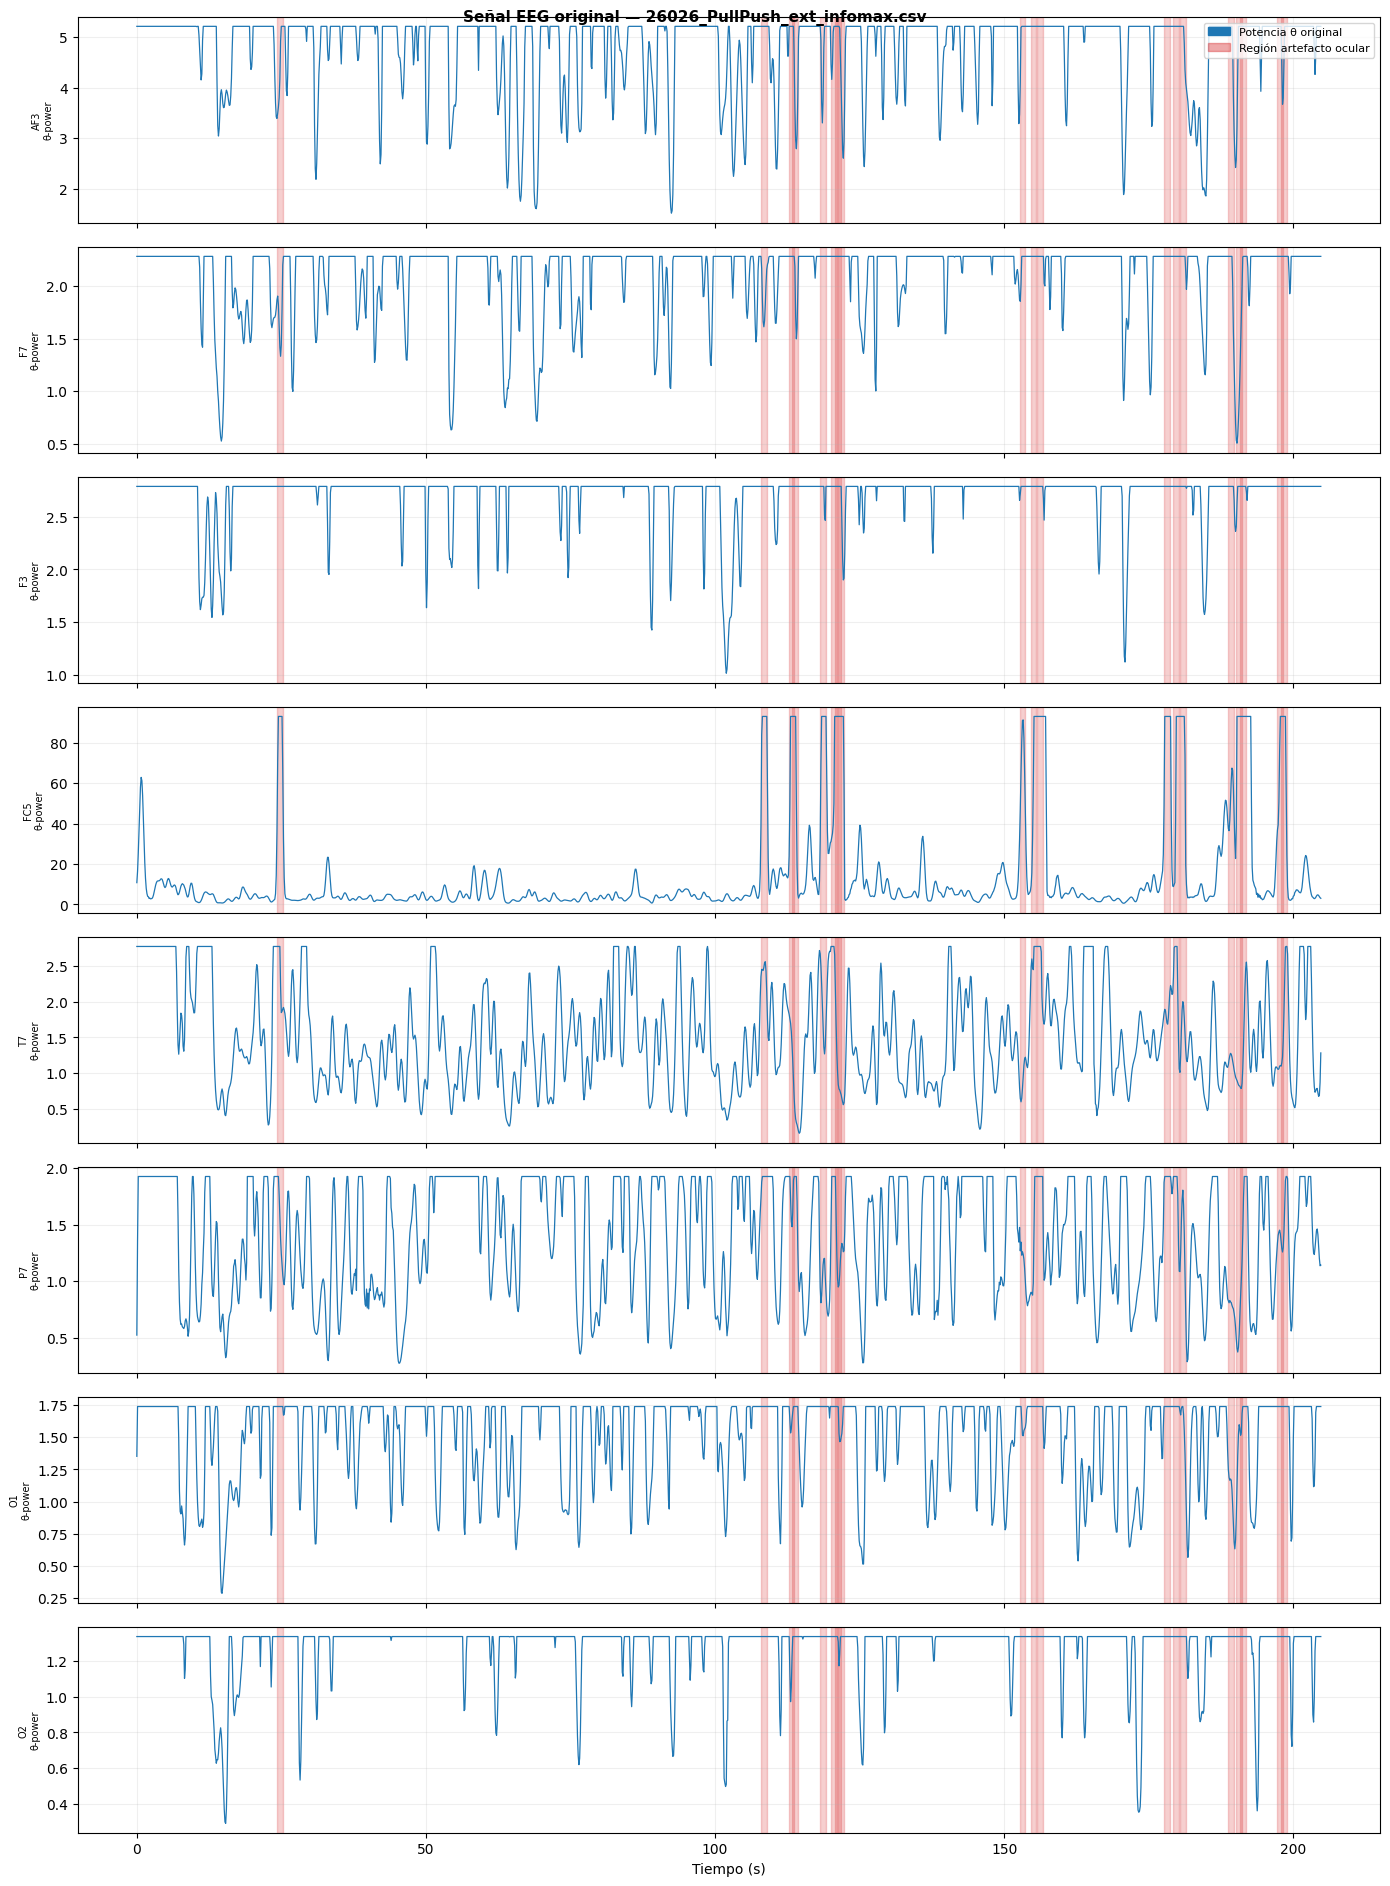

      → señal_general.png


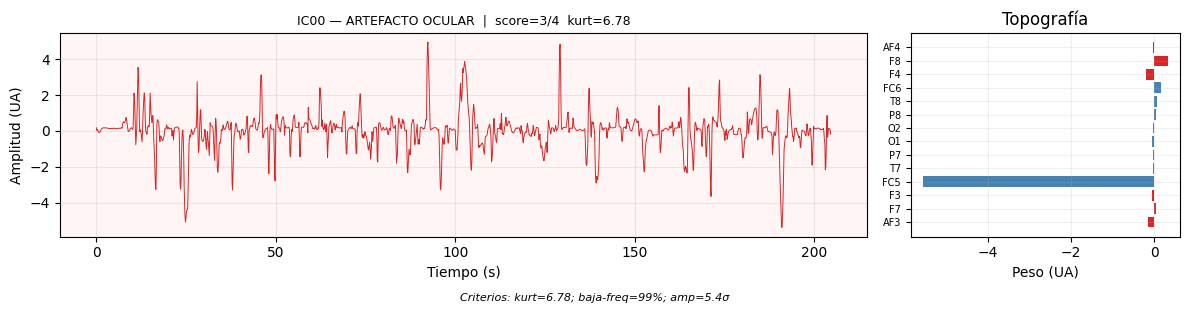

      → IC00.png


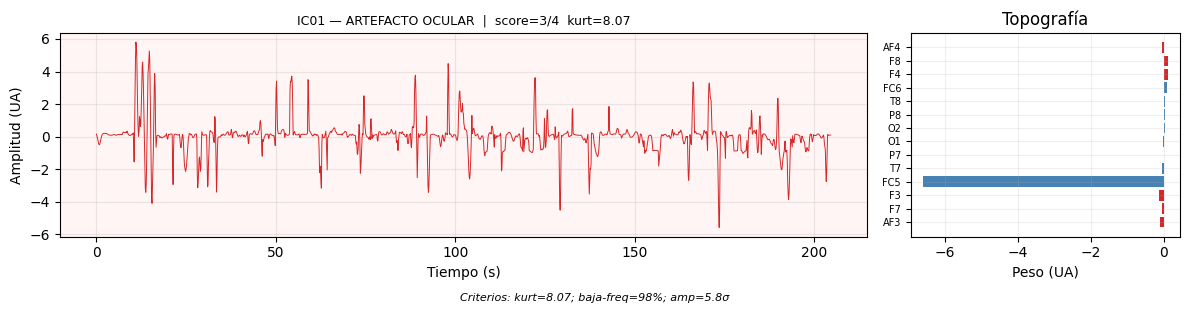

      → IC01.png


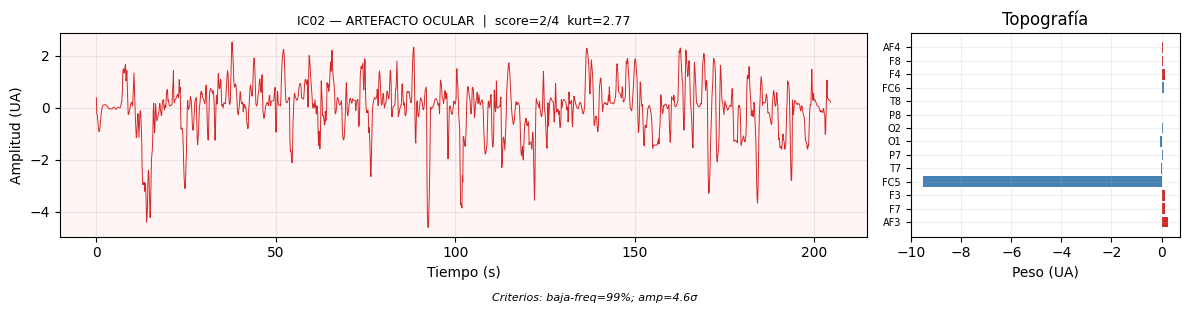

      → IC02.png


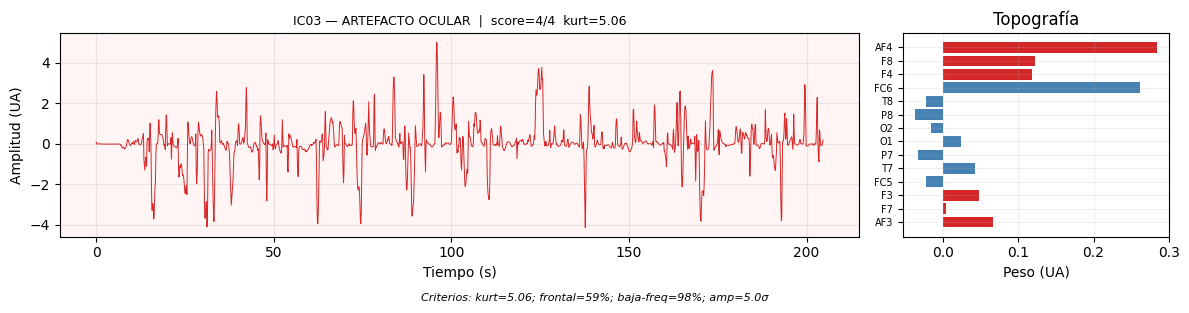

      → IC03.png


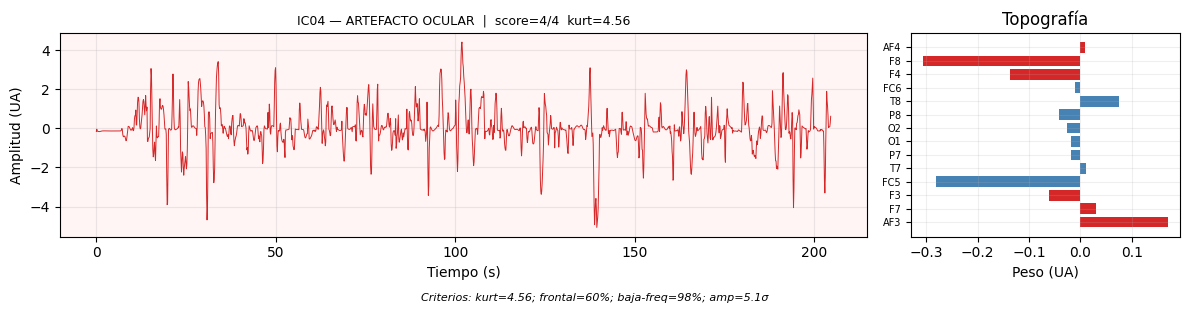

      → IC04.png


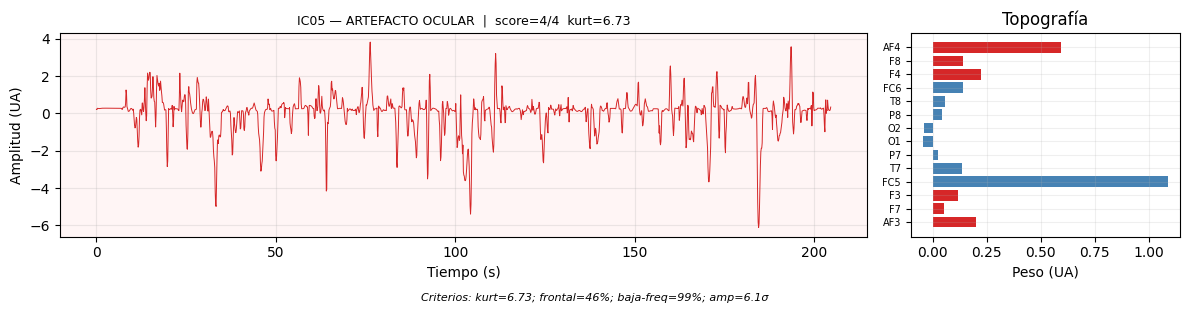

      → IC05.png


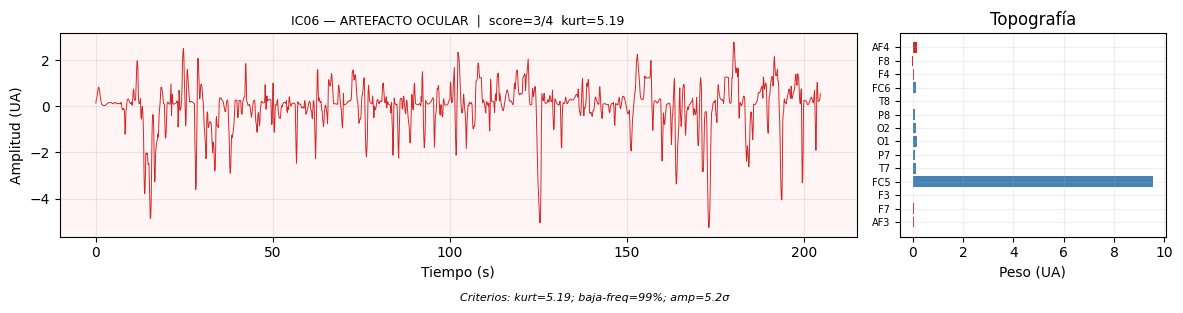

      → IC06.png


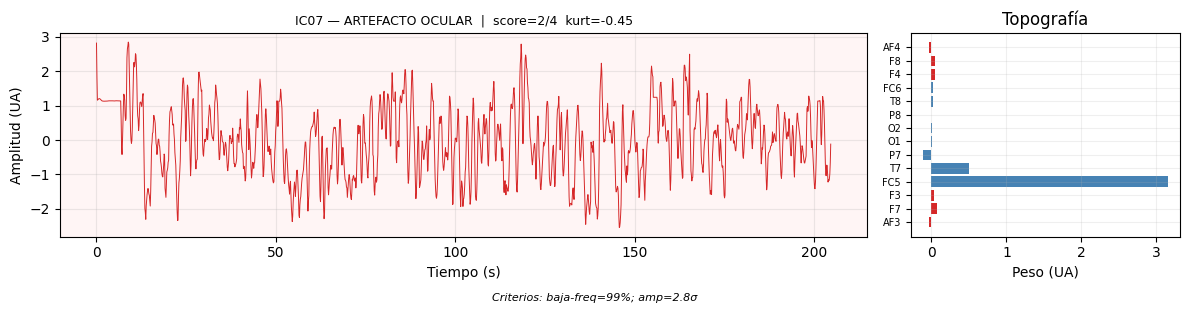

      → IC07.png


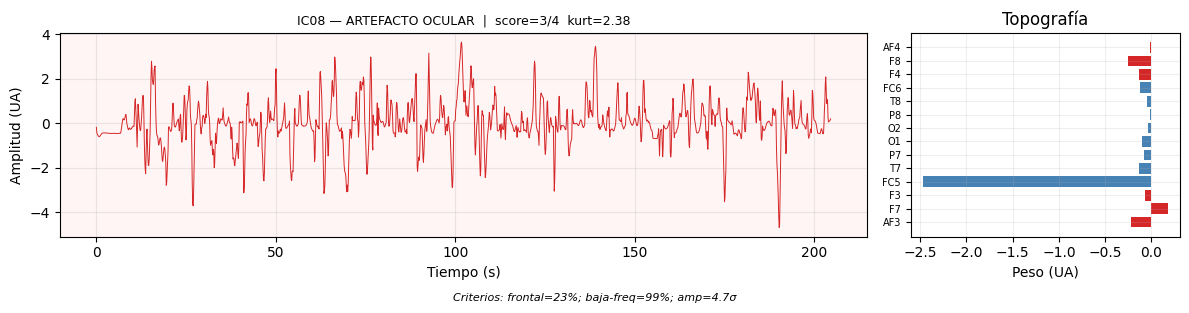

      → IC08.png


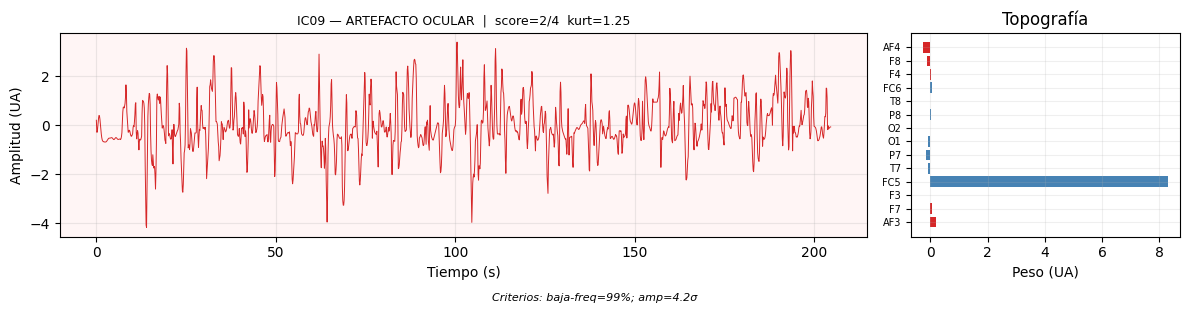

      → IC09.png


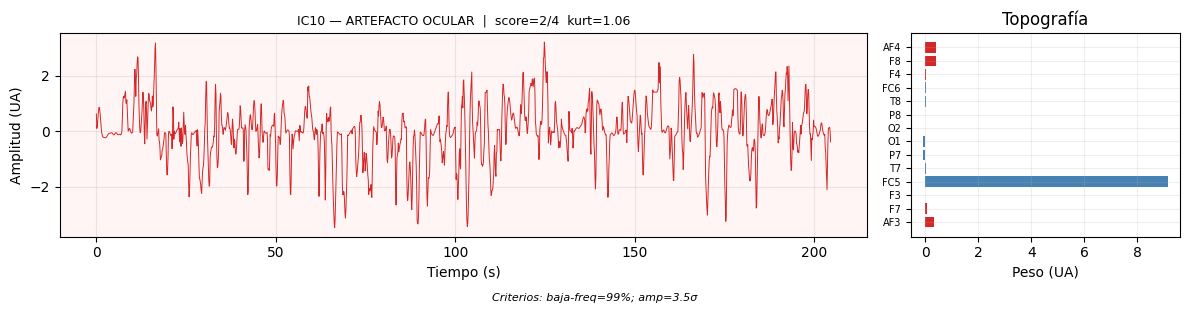

      → IC10.png


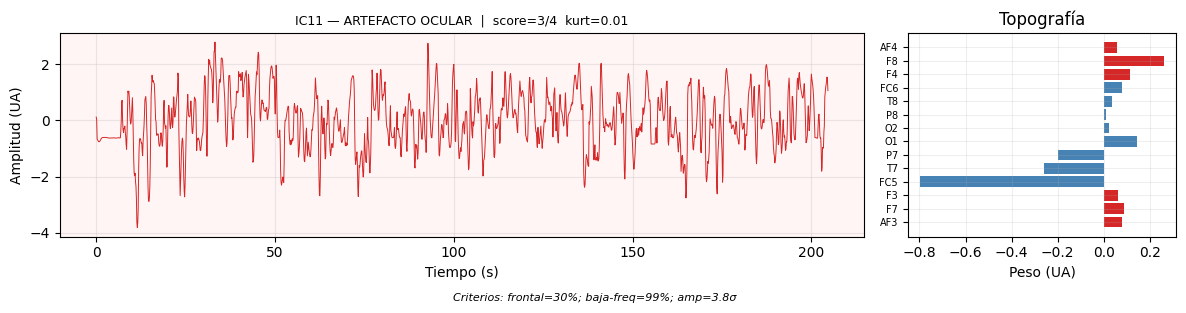

      → IC11.png


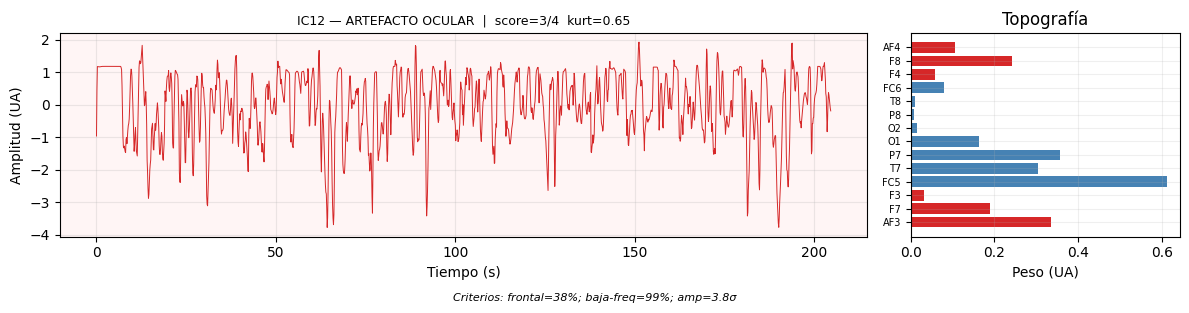

      → IC12.png


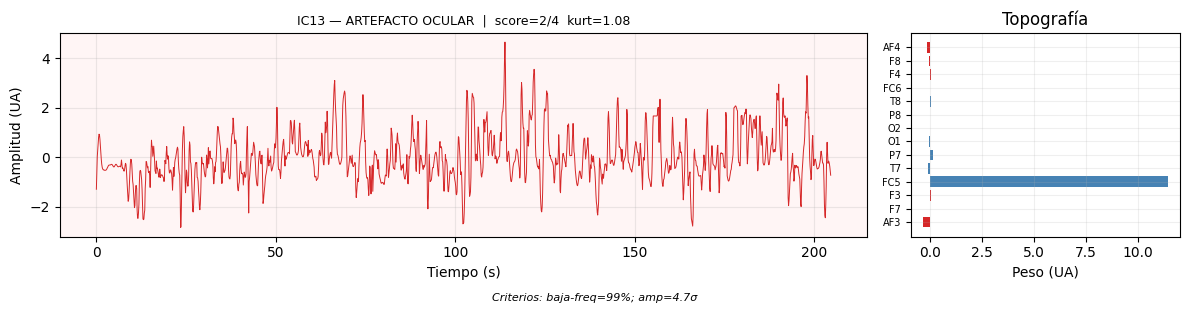

      → IC13.png


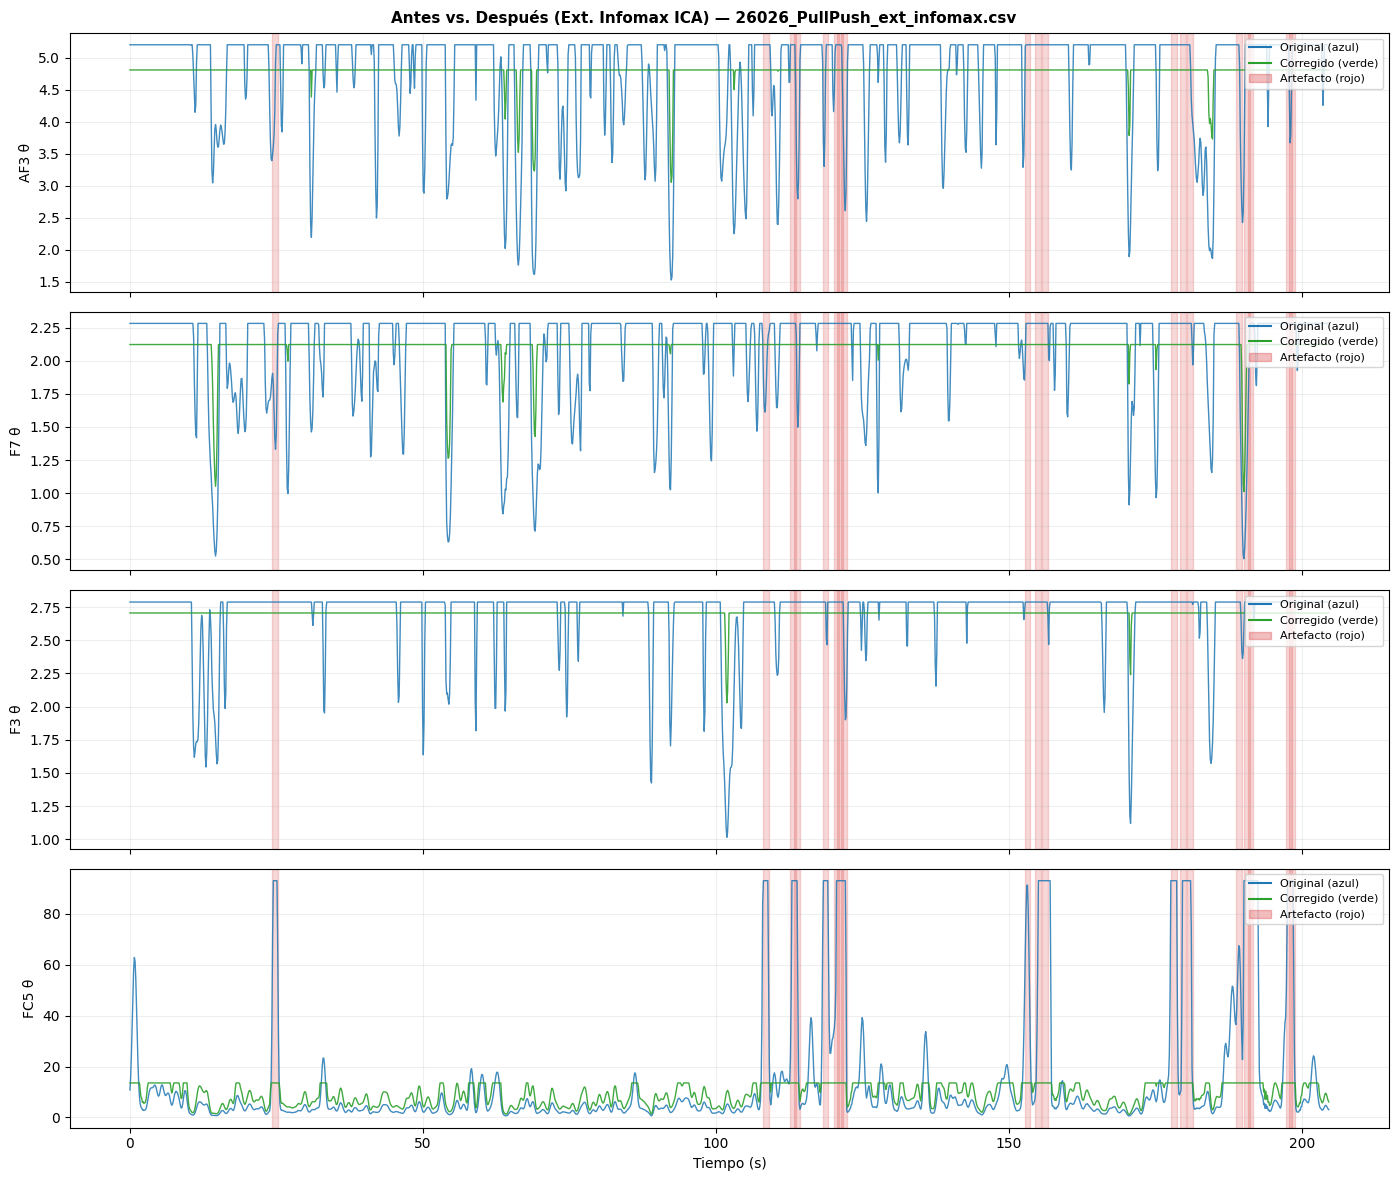

      → antes_despues.png


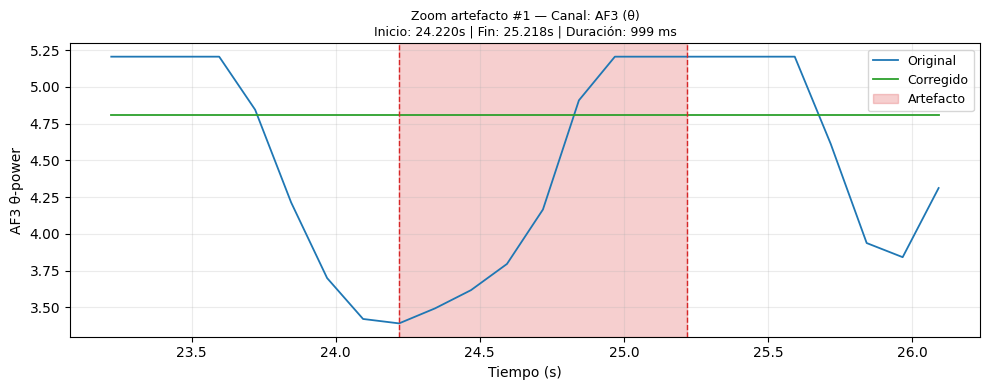

      → zoom_01.png


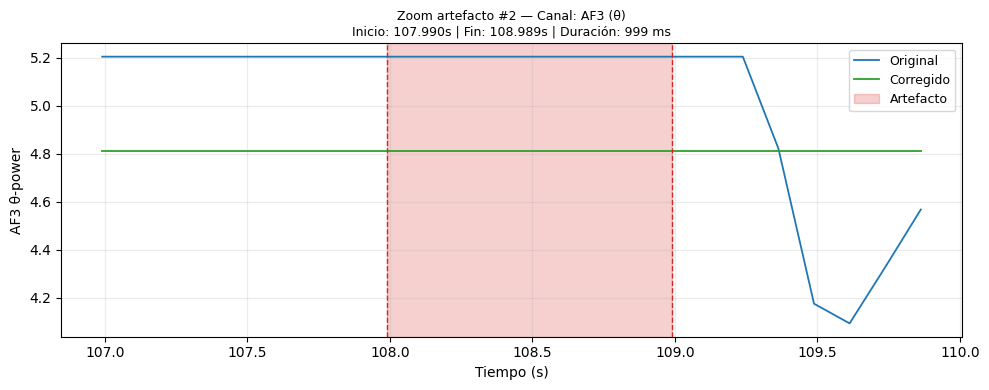

      → zoom_02.png


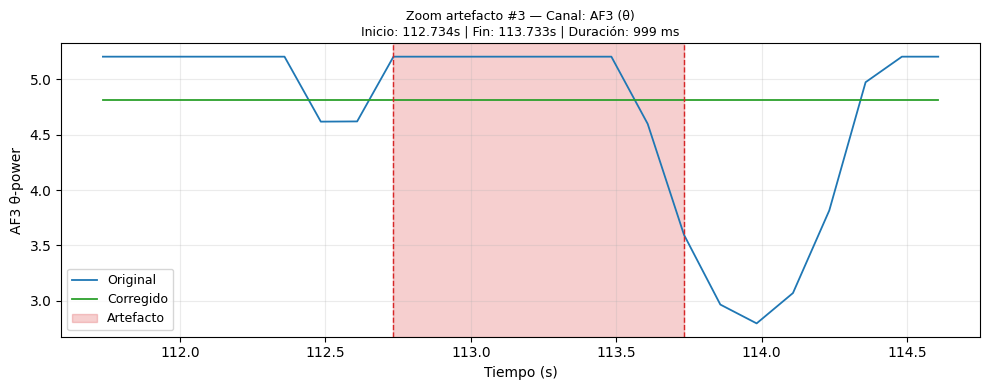

      → zoom_03.png


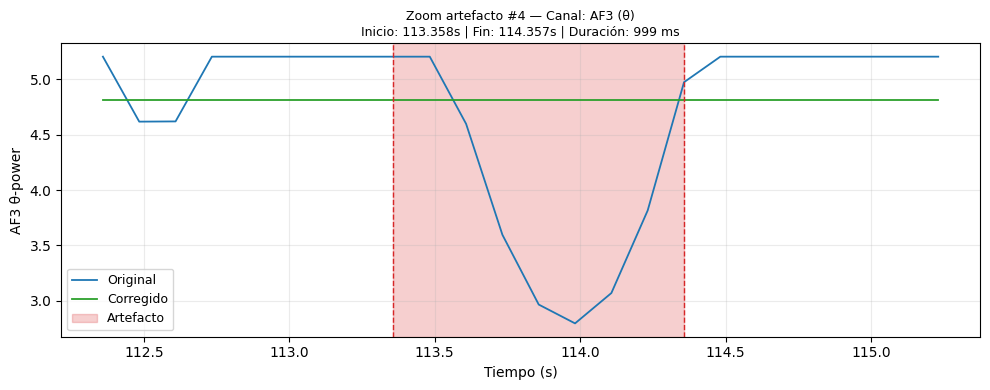

      → zoom_04.png


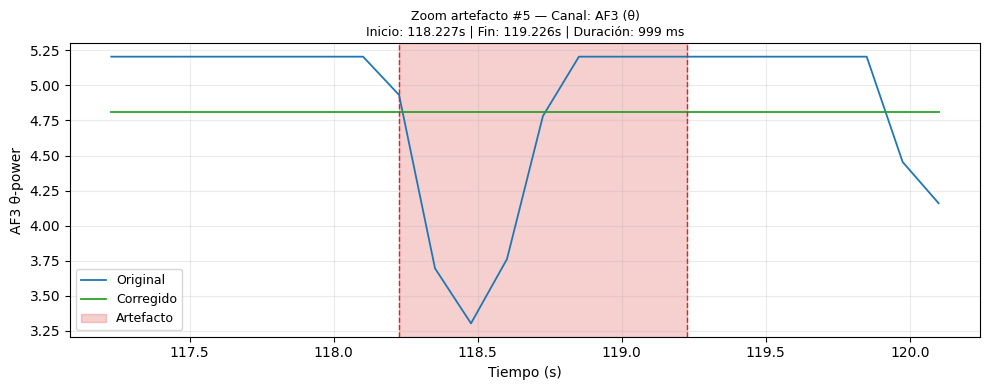

      → zoom_05.png


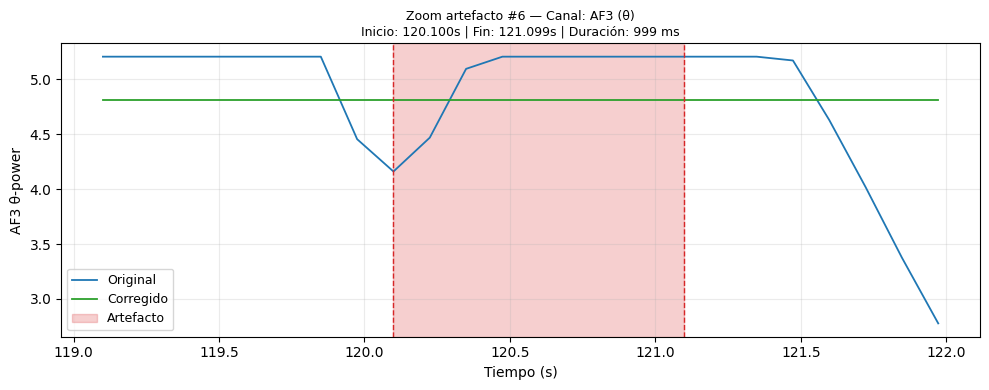

      → zoom_06.png


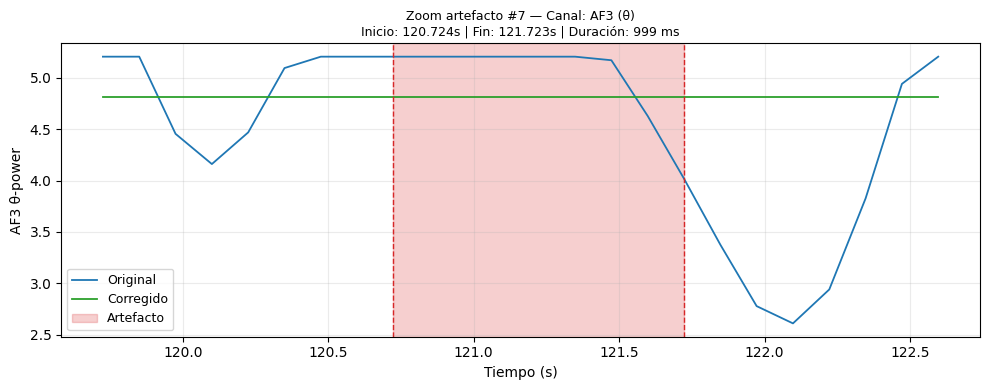

      → zoom_07.png


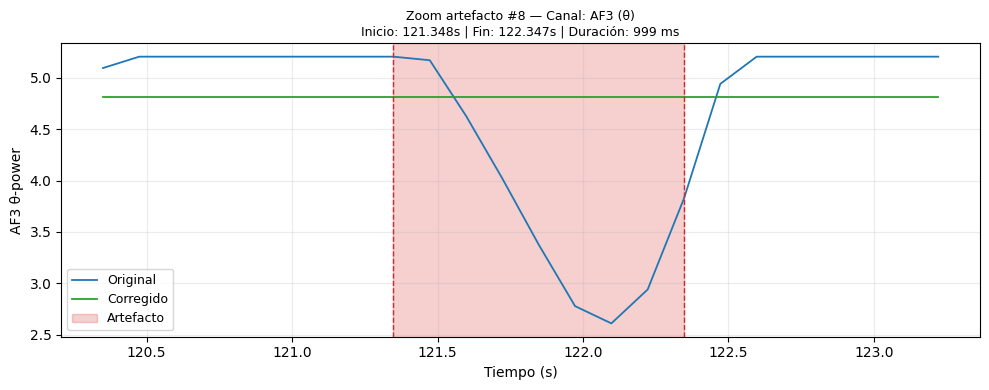

      → zoom_08.png


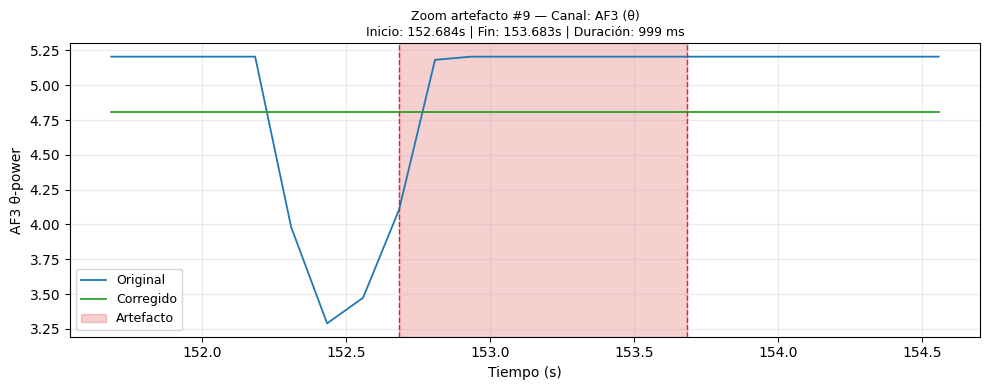

      → zoom_09.png


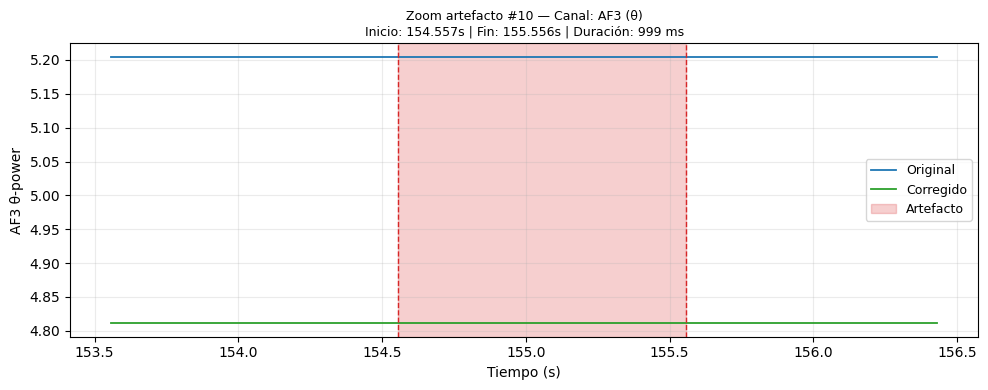

      → zoom_10.png


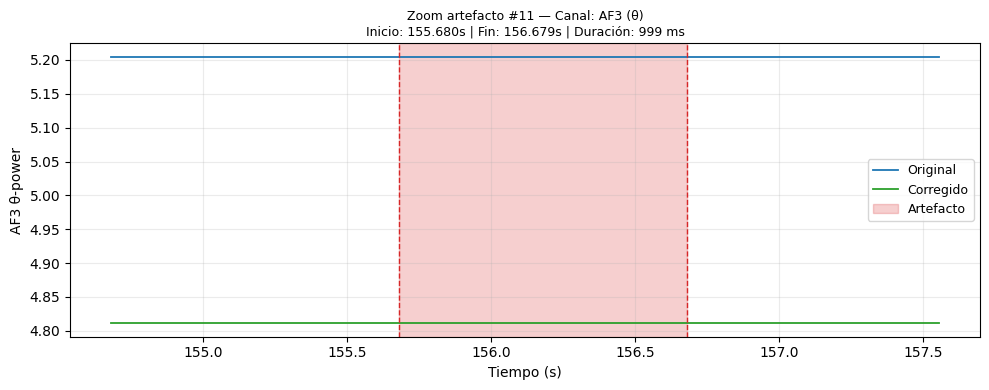

      → zoom_11.png


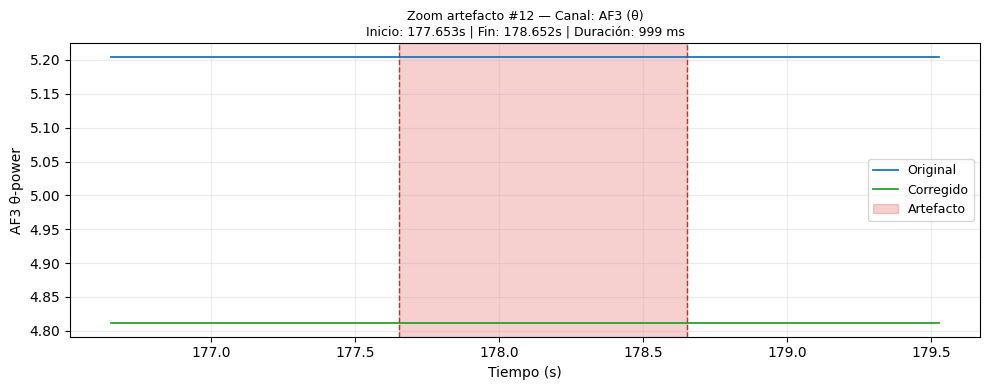

      → zoom_12.png


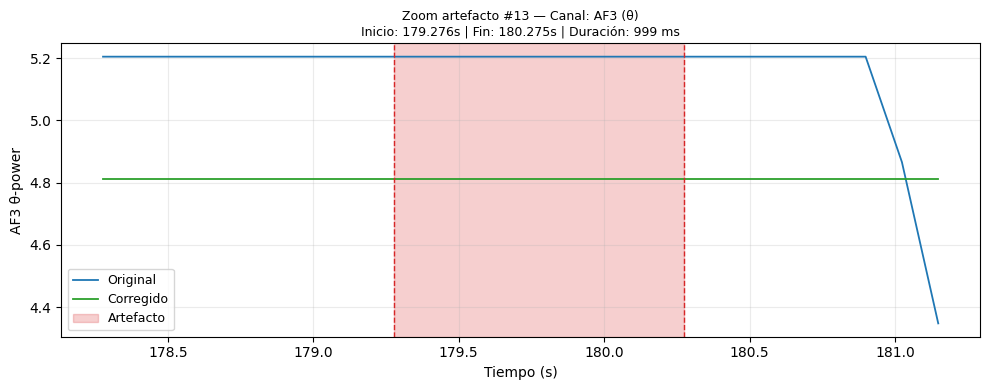

      → zoom_13.png


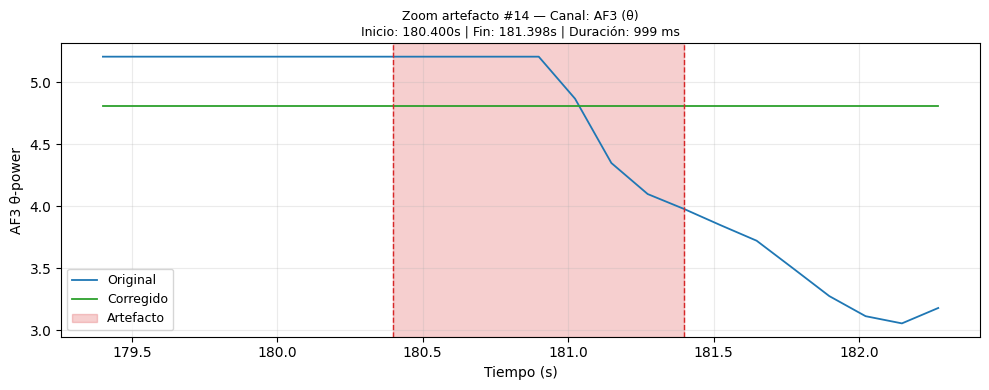

      → zoom_14.png


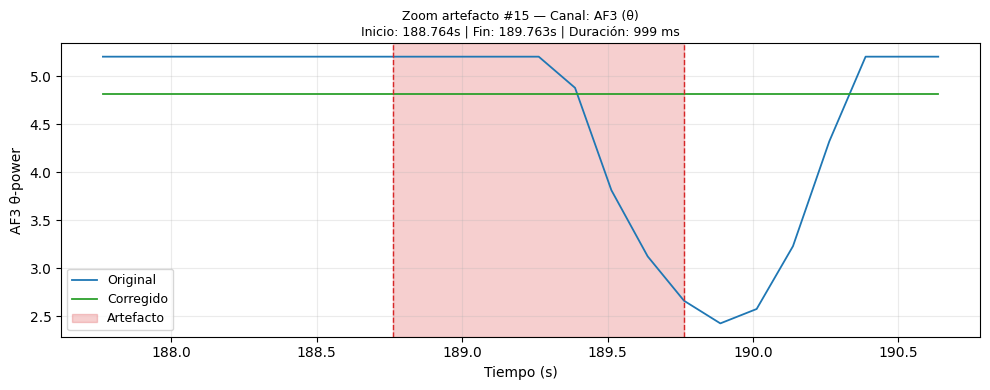

      → zoom_15.png


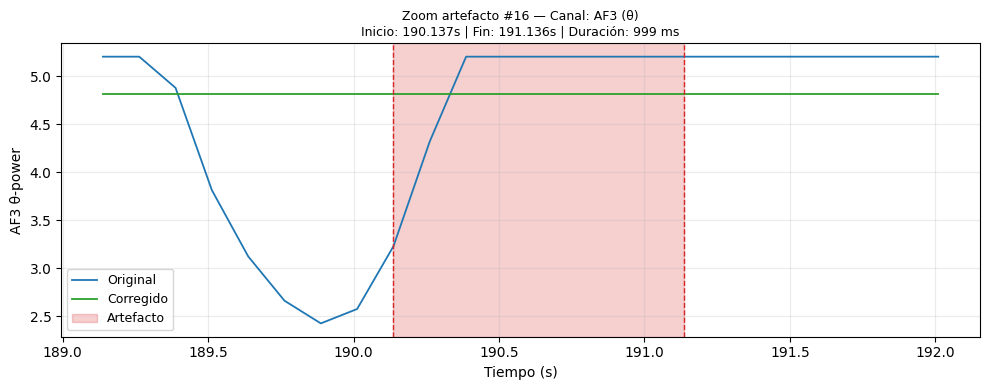

      → zoom_16.png


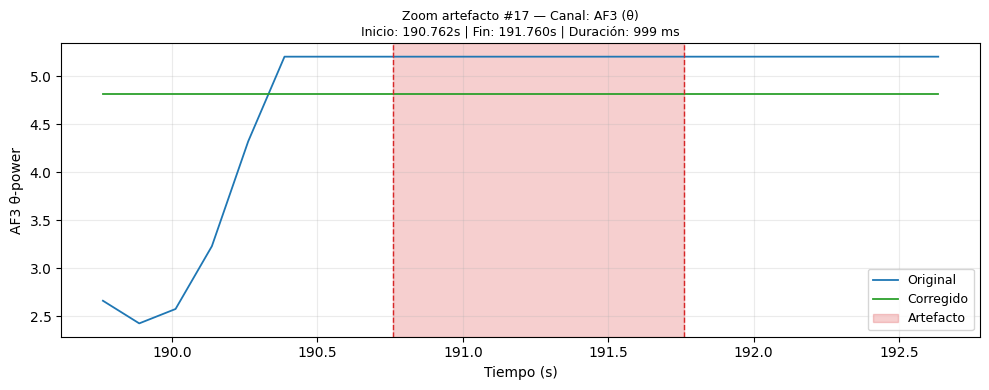

      → zoom_17.png


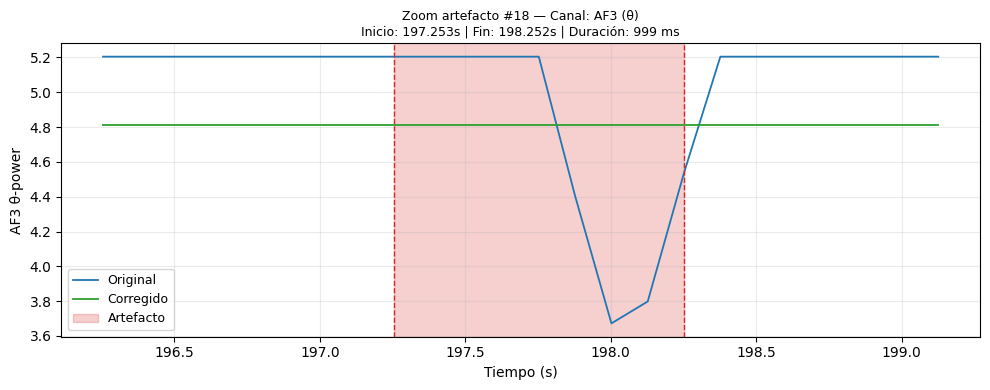

      → zoom_18.png


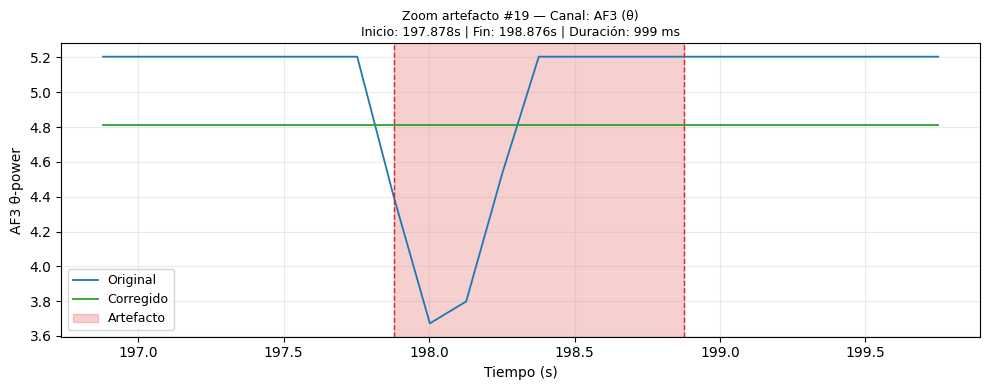

      → zoom_19.png


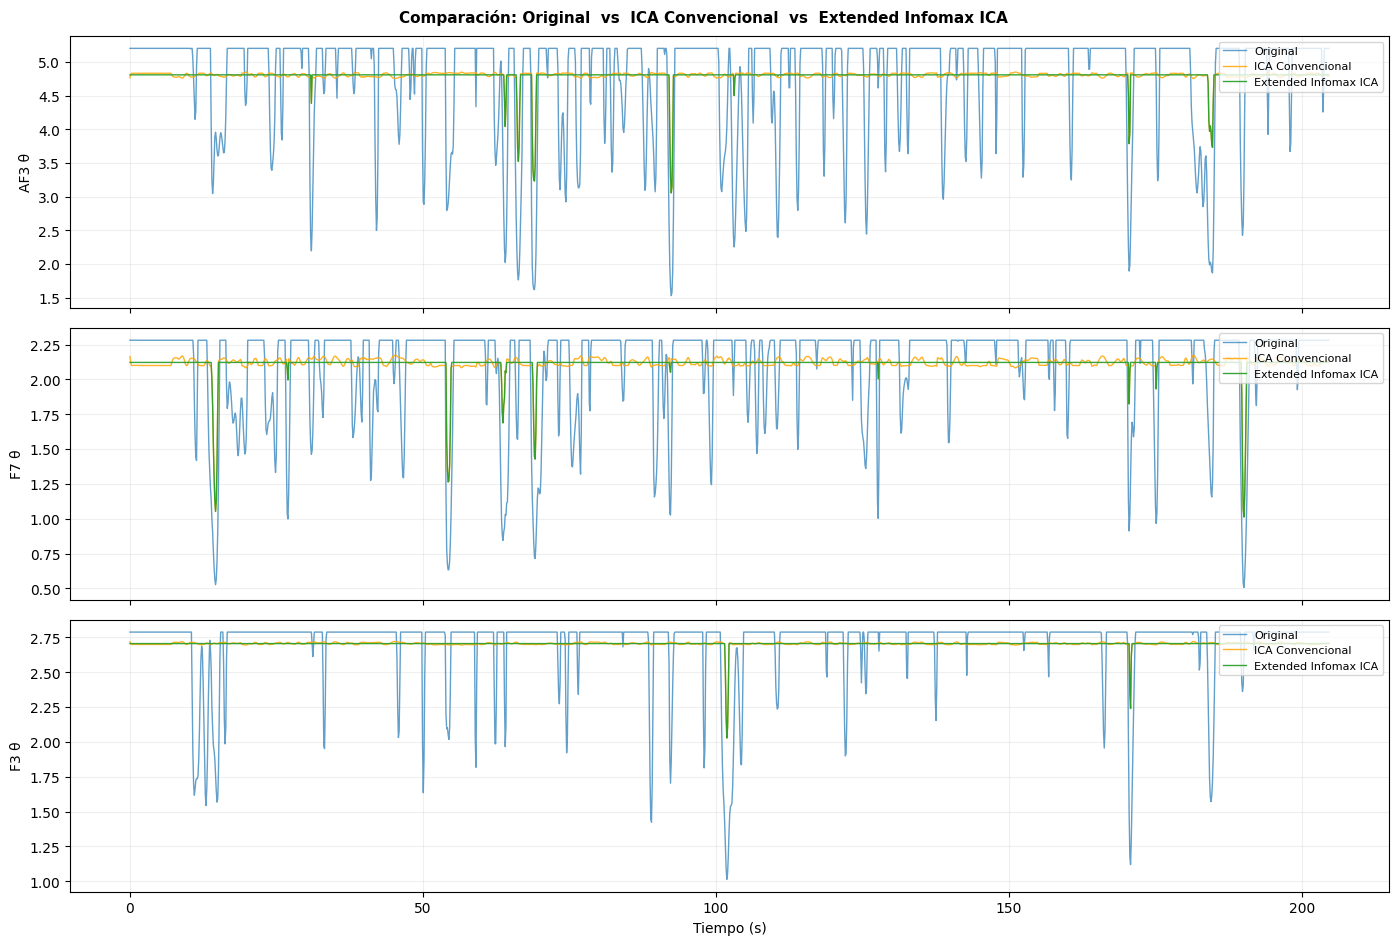

      → comparacion.png
  Métricas — Ext.Infomax: red_amp=85.4%, corr=0.4401  |  ICA conv: red_amp=84.4%, corr=0.4412

────────────────────────────────────────────────────────────
  RESULTADOS — 26026_PullPush_ext_infomax.csv
────────────────────────────────────────────────────────────

  Métricas comparativas:


,Método,Comp. oculares,Reducción amp. (%),Reducción var. (%),Correlación,Tiempo (s)
0,Extended Infomax ICA,14 / 14,85.4,80.6,0.4401,8.06
1,ICA Convencional (FastICA),13 / 14,84.4,80.6,0.4412,0.10



  Clasificación de componentes ICA (Extended Infomax):


,Componente,Clasificación,Score,Kurtosis,Proj. frontal,Baja freq.,Amp. relativa,Criterios
0,IC00,OCULAR ⚠,3/4,6.784,12%,99%,5.39σ,kurt=6.78; baja-freq=99%; amp=5.4σ
1,IC01,OCULAR ⚠,3/4,8.075,7%,98%,5.81σ,kurt=8.07; baja-freq=98%; amp=5.8σ
2,IC02,OCULAR ⚠,2/4,2.773,7%,99%,4.60σ,baja-freq=99%; amp=4.6σ
3,IC03,OCULAR ⚠,4/4,5.060,59%,98%,5.03σ,kurt=5.06; frontal=59%; baja-freq=98%; amp=5.0σ
4,IC04,OCULAR ⚠,4/4,4.562,60%,98%,5.07σ,kurt=4.56; frontal=60%; baja-freq=98%; amp=5.1σ
5,IC05,OCULAR ⚠,4/4,6.728,46%,99%,6.11σ,kurt=6.73; frontal=46%; baja-freq=99%; amp=6.1σ
6,IC06,OCULAR ⚠,3/4,5.188,4%,99%,5.25σ,kurt=5.19; baja-freq=99%; amp=5.2σ
7,IC07,OCULAR ⚠,2/4,-0.452,6%,99%,2.84σ,baja-freq=99%; amp=2.8σ
8,IC08,OCULAR ⚠,3/4,2.377,23%,99%,4.69σ,frontal=23%; baja-freq=99%; amp=4.7σ
9,IC09,OCULAR ⚠,2/4,1.247,7%,99%,4.18σ,baja-freq=99%; amp=4.2σ



  Segmentos de artefacto detectados (19):


...

,archivo,muestras,fs_hz,duracion_s,canales,comp_ICA_total,comp_oculares_ext,comp_oculares_conv,red_amp_ext_%,correlacion_ext,red_amp_conv_%,correlacion_conv,segmentos_detectados
0,26026_PullPush_ext_infomax.csv,1640,8.01,204.7,14,14,14,13,85.4,0.4401,84.4,0.4412,19



PROCESAMIENTO FINALIZADO
Archivos procesados : 1
Archivos con errores: 0
Reducción amp. media: 85.4%
Correlación media   : 0.4401
Descargando resultados en ZIP…


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


       MENÚ DE PROCESAMIENTO DE SEÑALES
1. Equipo 1 - Fast_ICA
2. Equipo 2 - Wavelet_ICA
3. Equipo 3 - Pasaband
4. Equipo 4 - InterferenciaModifier
5. Equipo 5 - ICA
6. Equipo 6 - ExtendInfomax_ICA
7. Equipo 7 - Artefacto_NoRaw
0. Salir
Selecciona una opción (0-7): 0
Saliendo del programa. ¡Hasta pronto!


In [3]:

def mostrar_menu():
    print("\n" + "=" * 50)
    print("       MENÚ DE PROCESAMIENTO DE SEÑALES")
    print("=" * 50)
    print("1. Equipo 1 - Fast_ICA")
    print("2. Equipo 2 - Wavelet_ICA")
    print("3. Equipo 3 - Pasaband")
    print("4. Equipo 4 - InterferenciaModifier")
    print("5. Equipo 5 - ICA")
    print("6. Equipo 6 - ExtendInfomax_ICA")
    print("7. Equipo 7 - Artefacto_NoRaw")
    print("0. Salir")
    print("=" * 50)


def ejecutar_equipo(opcion):
    temas = {
        "1": ("Equipo 1", "Fast_ICA"),
        "2": ("Equipo 2", "Wavelet_ICA"),
        "3": ("Equipo 3", "Pasaband"),
        "4": ("Equipo 4", "InterferenciaModifier"),
        "5": ("Equipo 5", "ICA"),
        "6": ("Equipo 6", "ExtendInfomax_ICA"),
        "7": ("Equipo 7", "Artefacto_NoRaw")
    }

    if opcion in temas:
        equipo, tema = temas[opcion]
        print("\n" + "-" * 40)
        print(f"Seleccionaste: {equipo}")
        print(f"Tema: {tema}")
        print("-" * 40)

        # Aquí puedes agregar el código específico
        # para ejecutar el procesamiento de cada tema.
        # Implementación de la opción 6
        if opcion == "6":
            ejecutar_equipo6()


    else:
        print("Opción no válida. Intenta nuevamente.")


def main():
    while True:
        mostrar_menu()
        opcion = input("Selecciona una opción (0-7): ").strip()

        if opcion == "0":
            print("Saliendo del programa. ¡Hasta pronto!")
            break

        ejecutar_equipo(opcion)


if __name__ == "__main__":
    main()
